# Radar de Fraude: detecção automática de transações fraudulentas

Hoje a triagem de fraude é quase toda manual: alguém olha transação por transação e decide. Isso não escala,
e o score interno que deveria ajudar, como vamos ver, não ajuda. A pergunta que guiou este trabalho foi simples:
**dá para dizer, para cada transação, o que fazer com ela (aprovar, revisar ou bloquear) e por quê?**

| O que foi entregue | Onde está |
|---|---|
| Este notebook, com todo o raciocínio | `case_fraude.ipynb` |
| Base de jan/2026 classificada | `entrega/transacoes_jan2026_classificadas.csv` |
| Apresentação | `entrega/apresentacao_case_fraude.pdf` |
| Dashboard online + código | link no `README.md` e no PDF |

### O caminho que segui
1. Entender o problema e decidir como medir sucesso
2. Carregar os dados e checar a qualidade
3. Explorar os dados a partir de hipóteses
4. Criar variáveis, incluindo feriados de uma API externa
5. Separar treino e teste respeitando o tempo
6. Modelar: baselines simples → AutoGluon → um campeão
7. Avaliar o campeão
8. Transformar probabilidade em decisão e em R$
9. Explicar cada alerta com SHAP e escrever o motivo em português para o analista
10. Classificar janeiro/2026
11. Monitorar drift
12. Conclusões e próximos passos

## 1. Entendendo o problema

Antes de qualquer modelo, vale lembrar que em fraude existem dois jeitos de errar, e eles não custam o mesmo:

| Situação | O que acontece | Quanto custa |
|---|---|---|
| **Fraude aprovada** (falso negativo) | o dinheiro sai | ≈ o valor da transação |
| **Cliente bom barrado** (falso positivo) | atrito, ligação no SAC, risco de perder o cliente | um custo fixo por caso |
| **Revisão manual** | tempo do analista | um custo fixo por caso |

Isso muda o desenho da solução em três pontos:

- **Acurácia não serve aqui.** Só ~4% das transações são fraude, então um modelo que aprova tudo "acerta" 96% e não
  ajuda em nada. Por isso uso a **PR-AUC (average precision)**, que olha justamente para a classe rara.
- **O modelo dá uma probabilidade, e a decisão vem depois.** Em vez do corte padrão de 0,5, escolho os limiares
  pelo **custo em reais** de cada erro.
- **Não é só sim ou não.** São três faixas: **aprovar, revisar ou bloquear**. A fila manual continua existindo,
  mas fica bem menor e ordenada pelo risco.

In [1]:
import json, os, time, warnings
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))
try:  # evita o aviso do joblib (chamada ao 'wmic', removido do Windows 11)
    import joblib.externals.loky.backend.context as _loky_ctx
    _loky_ctx.physical_cores_cache = os.cpu_count()
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
SEED = 42
np.random.seed(SEED)

# True  → treina o benchmark AutoGluon (~25 min) e salva os resultados em artefatos/autogluon_resultados/
# False → lê os resultados salvos e roda o notebook inteiro em poucos minutos só com LightGBM
USAR_AUTOGLUON = False

# ---- caminhos ---------------------------------------------------------------
BASE = Path(".")
ARQ_HIST = BASE / "transacoes_historico_2025.csv"
ARQ_JAN = BASE / "transacoes_jan2026.csv"
ARQ_FERIADOS = BASE / "dados_externos" / "feriados_brasilapi.csv"
DIR_ENTREGA = BASE / "entrega"; DIR_ENTREGA.mkdir(exist_ok=True)
DIR_ART = BASE / "artefatos"; DIR_ART.mkdir(exist_ok=True)
DIR_FIG = DIR_ART / "figs"; DIR_FIG.mkdir(exist_ok=True)
DIR_APP = BASE / "app"; (DIR_APP / "dados").mkdir(parents=True, exist_ok=True)
DIR_AG = DIR_ART / "autogluon_resultados"; DIR_AG.mkdir(exist_ok=True)

# ---- premissas de negócio (explícitas e fáceis de mudar) --------------------
CUSTO_REVISAO = 4.0      # R$ por transação revisada (~5 min de analista a ~R$48/h)
CUSTO_BLOQUEIO_INDEVIDO = 15.0  # R$ por cliente legítimo bloqueado (atrito/SAC/churn)
MINUTOS_POR_REVISAO = 5

# ---- identidade visual dos gráficos -------------------------------------------
from matplotlib import font_manager as fm, transforms as mtrans
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

for _f in (BASE / "extras" / "fontes").glob("*.ttf"):
    fm.fontManager.addfont(str(_f))
FONTE = "IBM Plex Sans" if any(f.name == "IBM Plex Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"

# paleta validada (daltonismo + contraste): azul = padrão, magenta = risco, violeta = 3ª série
AZUL, MAGENTA, VIOLETA = "#3346d3", "#e0005f", "#8a3fc7"
CINZA, TINTA, TINTA2, MUDO, GRADE, NAVY = "#c4c6d4", "#11163a", "#5a5f7a", "#9a9db3", "#eceef4", "#0e1236"
VAZIO = "#f3f4f8"  # célula/trilho vazio
GRADIENTE = LinearSegmentedColormap.from_list("marca", ["#2b39c4", VIOLETA, MAGENTA])
SEQ_RISCO = LinearSegmentedColormap.from_list("risco", ["#ffffff", "#f9d3e2", "#ef6a9c", MAGENTA, "#7a0034"])
DIVERG = LinearSegmentedColormap.from_list("divergente", [AZUL, "#d9dae3", MAGENTA])

plt.rcParams.update({
    "font.family": FONTE, "font.size": 10, "text.color": TINTA,
    "figure.dpi": 110, "savefig.dpi": 180, "savefig.bbox": "tight", "savefig.pad_inches": 0.25,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": CINZA, "axes.linewidth": 1, "axes.labelcolor": TINTA2, "axes.labelsize": 9.5,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.major.pad": 6, "ytick.major.pad": 6,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "medium", "axes.titlecolor": TINTA, "axes.titlelocation": "left",
    "axes.titlepad": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.solid_capstyle": "round",
    "text.parse_math": False,  # "R$" é texto, não fórmula
})


def pct_br(v, d=0):
    return f"{v:.{d}%}".replace(".", ",")


def brl(v):
    return f"R$ {v:,.0f}".replace(",", ".")


def eixo_pct(ax, eixo="y", d=0):
    fmt = mtick.FuncFormatter(lambda x, _: pct_br(x, d))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(fmt)


def arredondar(ax, barras, raio=0.24, horizontal=False):
    """Troca as barras retangulares por barras com cantos arredondados (círculo de verdade, sem distorção)."""
    ax.figure.canvas.draw()
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    a = (abs(y1 - y0) / bb.height) / (abs(x1 - x0) / bb.width)  # unidades de y por unidade de x, no mesmo pixel
    novas = []
    for b in barras:
        x, y, w, h = b.get_x(), b.get_y(), b.get_width(), b.get_height()
        if w == 0 or h == 0:
            novas.append(b); continue
        x, w = (x + w, -w) if w < 0 else (x, w)
        y, h = (y + h, -h) if h < 0 else (y, h)
        r = min(h * raio / a if horizontal else w * raio, w / 2, h / a / 2)
        p = FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", mutation_aspect=a,
                           facecolor=b.get_facecolor(), edgecolor="none", zorder=b.get_zorder())
        ax.add_patch(p); b.remove(); novas.append(p)
    return novas


def legenda_chips(ax, itens, **kw):
    """Legenda com marcadores redondos (itens = [(rótulo, cor), ...])."""
    h = [Line2D([], [], marker="o", ls="", ms=8, mfc=c, mec=c) for _, c in itens]
    kw = {"ncol": len(itens), "handletextpad": 0.3, "columnspacing": 1.4, **kw}
    return ax.legend(h, [r for r, _ in itens], **kw)


def barra_gradiente(ax, barras, horizontal=False):
    """Pinta as barras de destaque com o gradiente da marca (azul → violeta → magenta)."""
    lim = ax.get_xlim(), ax.get_ylim()
    g = np.linspace(0, 1, 256)
    for b in barras:
        x, y, w, h = b.get_x(), b.get_y(), b.get_width(), b.get_height()
        if w == 0 or h == 0:
            continue
        im = ax.imshow(g.reshape(1, -1) if horizontal else g.reshape(-1, 1), cmap=GRADIENTE, aspect="auto",
                       origin="lower", extent=[x, x + w, y, y + h], zorder=b.get_zorder() + 0.1, interpolation="bicubic")
        im.set_clip_path(b)
        b.set_facecolor("none"); b.set_edgecolor("none")
    ax.set_xlim(lim[0]); ax.set_ylim(lim[1])


def cabecalho(fig, titulo, subtitulo="", nota=""):
    """Título-manchete à esquerda, subtítulo, régua em gradiente e nota de rodapé (fora da área do gráfico)."""
    fig.canvas.draw()
    r, inv = fig.canvas.get_renderer(), fig.transFigure.inverted()
    caixas = [ax.get_tightbbox(r).transformed(inv) for ax in fig.axes if ax.get_visible()]
    x0, y1, y0 = min(c.x0 for c in caixas), max(c.y1 for c in caixas), min(c.y0 for c in caixas)
    pt = lambda p: mtrans.offset_copy(fig.transFigure, fig=fig, x=0, y=p, units="points")
    fig.text(x0, y1, subtitulo, transform=pt(14), fontsize=10, color=TINTA2, va="bottom")
    fig.text(x0, y1, titulo, transform=pt(32 if subtitulo else 14), fontsize=17, fontweight="light",
             color=TINTA, va="bottom")
    # régua: barra fina em gradiente logo abaixo do subtítulo
    alt_in, larg_in = fig.get_size_inches()[1], fig.get_size_inches()[0]
    ax_r = fig.add_axes([x0, y1 + 6 / 72 / alt_in, 1.6 / larg_in, 2.2 / 72 / alt_in])
    ax_r.imshow(np.linspace(0, 1, 256).reshape(1, -1), cmap=GRADIENTE, aspect="auto")
    ax_r.set_axis_off()
    if nota:
        fig.text(x0, y0, nota, transform=pt(-16), fontsize=8, color=MUDO, va="top")


def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png")

METRICAS = {}  # tudo que vai para a apresentação/app é acumulado aqui

## 2. Carga e qualidade dos dados

Primeiro, carregar as duas bases (2025 com o rótulo de fraude e janeiro/2026 sem) e ver se dá para confiar nelas.

In [2]:
hist = pd.read_csv(ARQ_HIST, parse_dates=["datahora_transacao"], encoding="utf-8")
jan = pd.read_csv(ARQ_JAN, parse_dates=["datahora_transacao"], encoding="utf-8")
hist["flag_fraude"] = hist["flag_fraude"].astype(bool)

print(f"Histórico 2025: {hist.shape[0]:,} linhas × {hist.shape[1]} colunas | "
      f"{hist.datahora_transacao.min()} → {hist.datahora_transacao.max()}")
print(f"Janeiro 2026  : {jan.shape[0]:,} linhas × {jan.shape[1]} colunas | "
      f"{jan.datahora_transacao.min()} → {jan.datahora_transacao.max()}")
print("Colunas só no histórico:", set(hist.columns) - set(jan.columns))
hist.head()

Histórico 2025: 523,525 linhas × 15 colunas | 2025-01-01 00:00:00 → 2025-12-31 23:59:00
Janeiro 2026  : 44,451 linhas × 14 colunas | 2026-01-01 00:00:00 → 2026-01-31 23:58:00
Colunas só no histórico: {'flag_fraude'}


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.1200,Cliente_16621,Recife,False,desktop,False,31.5000,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.7400,Cliente_12596,Recife,False,mobile,False,28.1000,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.9400,Cliente_10474,Salvador,False,mobile,True,29.1000,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.7200,Cliente_20661,Salvador,False,mobile,True,28.6000,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.8500,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2000,50814-648,892,madrugada,baixo,Sudeste


In [3]:
qualidade = pd.DataFrame({
    "tipo": hist.dtypes.astype(str),
    "nulos": hist.isna().sum(),
    "distintos_2025": hist.nunique(),
    "distintos_jan26": jan.reindex(columns=hist.columns).nunique(),
})
print("Linhas duplicadas:", hist.duplicated().sum())
print("Intervalo entre transações:", hist.datahora_transacao.diff().value_counts().head(3).to_dict())
print("Clientes de jan/26 que já existem em 2025:", f"{jan.nome_cliente.isin(hist.nome_cliente).mean():.1%}")
qualidade

Linhas duplicadas: 0
Intervalo entre transações: {Timedelta('0 days 00:01:00'): 521452, Timedelta('0 days 00:02:00'): 2069, Timedelta('0 days 00:03:00'): 3}


Clientes de jan/26 que já existem em 2025: 100.0%


,tipo,nulos,distintos_2025,distintos_jan26
datahora_transacao,datetime64[us],0,523525,44451
nome_estabelecimento,str,0,10,10
tipo_estabelecimento,str,0,6,6
valor_transacao,float64,0,29246,10890
nome_cliente,str,0,26214,21290
cidade,str,0,7,7
flag_fraude,bool,0,2,0
device_type,str,0,3,3
is_new_device,bool,0,2,2
temperatura_celsius,float64,0,533,448


In [4]:
taxa = hist.flag_fraude.mean()
METRICAS["n_hist"] = int(len(hist)); METRICAS["n_jan"] = int(len(jan))
METRICAS["taxa_fraude_2025"] = float(taxa)
METRICAS["perda_fraude_2025"] = float(hist.loc[hist.flag_fraude, "valor_transacao"].sum())
print(f"Taxa de fraude: {taxa:.2%}  ({hist.flag_fraude.sum():,} fraudes)")
print(f"Valor total fraudado em 2025: R$ {METRICAS['perda_fraude_2025']:,.2f}")

Taxa de fraude: 3.91%  (20,485 fraudes)
Valor total fraudado em 2025: R$ 632,205.75


**O que encontrei na checagem**

Os dados estão limpos: sem nulos, sem duplicatas, tipos corretos e arquivo em UTF-8. Mas alguns detalhes mudam a
forma de ler os resultados:

- Há **exatamente uma transação por minuto**, sem interrupção. Isso indica dado sintético ou amostrado, então é
  esperado que os padrões apareçam bem mais "limpos" do que no mundo real.
- `codigo_postal` é praticamente único por linha. Na prática é um identificador, não uma variável, e vou descartá-lo.
- Todos os clientes de janeiro já aparecem no histórico, o que me permite testar variáveis de comportamento do cliente.
- A taxa de fraude fica em ~4%, um desbalanceamento típico desse tipo de problema.

## 3. Análise exploratória guiada por hipóteses

Em vez de gerar dezenas de gráficos e torcer para algo aparecer, escrevi antes o que eu esperava encontrar.
Cada gráfico abaixo responde a uma dessas perguntas:

| | Pergunta |
|---|---|
| H1 | A fraude se concentra em certos **horários**? |
| H2 | Um **dispositivo novo** é sinal de risco? |
| H3 | O **valor** da fraude tem um padrão (o fraudador "testa" com valores médios)? |
| H4 | Alguns **estabelecimentos ou cidades** são mais visados? |
| H5 | O **score interno** usado hoje separa fraude de não fraude? |
| H6 | A taxa de fraude é **estável ao longo do ano**? |

findfont: Failed to find font weight light for IBM Plex Sans, now using 300.


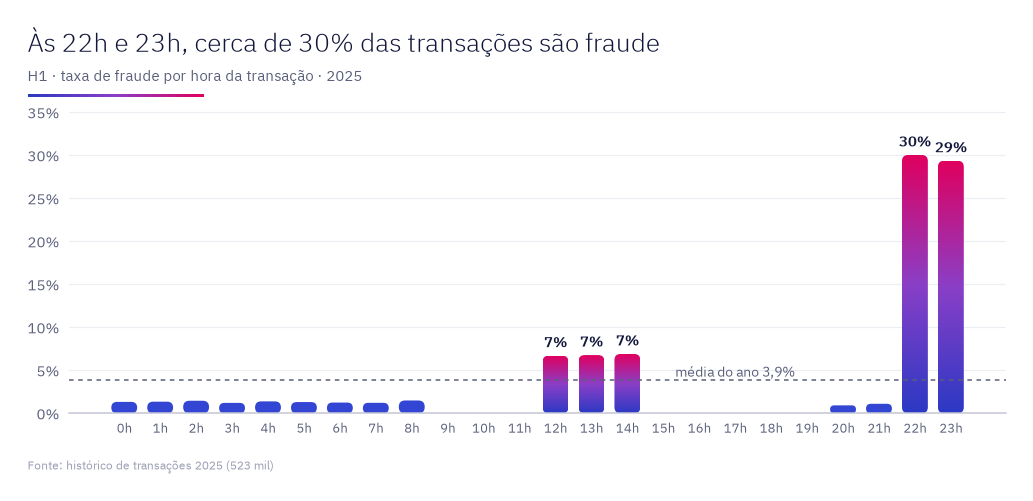

In [5]:
h = hist.copy()
h["hora"] = h.datahora_transacao.dt.hour
h["mes"] = h.datahora_transacao.dt.month

def taxa_por(col, data=h):
    t = data.groupby(col, observed=True).flag_fraude.agg(taxa="mean", n="size")
    return t

fig, ax = plt.subplots(figsize=(11, 3.6))
t = taxa_por("hora")
destaque = (t.taxa >= 0.05).values
barras = ax.bar(t.index, t.taxa, color=AZUL, width=0.72)
ax.set_ylim(0, t.taxa.max() * 1.18)
barras = arredondar(ax, barras)
barra_gradiente(ax, [b for b, d in zip(barras, destaque) if d])
ax.axhline(taxa, color=TINTA2, ls=(0, (3, 3)), lw=1)
ax.text(17, taxa, f"média do ano {pct_br(taxa, 1)}", va="bottom", ha="center", color=TINTA2, fontsize=9)
for x, v, d in zip(t.index, t.taxa, destaque):
    if d: ax.text(x, v + 0.006, pct_br(v), ha="center", va="bottom", fontsize=10, color=TINTA, fontweight="semibold")
eixo_pct(ax); ax.set_ylim(0, t.taxa.max() * 1.18)
ax.set_xticks(range(24)); ax.set_xticklabels([f"{i}h" for i in range(24)], fontsize=8.5)
cabecalho(fig, "Às 22h e 23h, cerca de 30% das transações são fraude",
          "H1 · taxa de fraude por hora da transação · 2025", "Fonte: histórico de transações 2025 (523 mil)")
salvar(fig, "eda_hora"); plt.show()


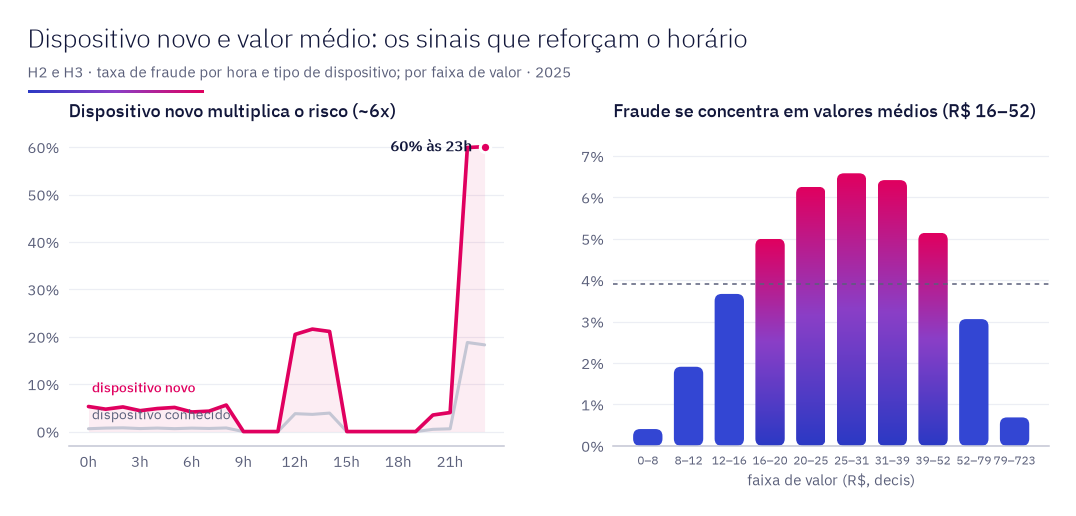

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw={"wspace": 0.25})
ct = h.pivot_table(index="hora", columns="is_new_device", values="flag_fraude", aggfunc="mean")
axes[0].plot(ct.index, ct[False], color=CINZA, lw=2)
axes[0].plot(ct.index, ct[True], color=MAGENTA, lw=2.4)
axes[0].fill_between(ct.index, ct[True], color=MAGENTA, alpha=0.07, lw=0)
axes[0].scatter([23], [ct.loc[23, True]], s=46, color=MAGENTA, edgecolor="white", lw=2, zorder=3)
axes[0].annotate(f"{pct_br(ct.loc[23, True])} às 23h", (23, ct.loc[23, True]), xytext=(-8, 0), textcoords="offset points",
                 ha="right", va="center", color=TINTA, fontweight="semibold", fontsize=9.5)
axes[0].text(0.2, ct.loc[0, True] + 0.03, "dispositivo novo", color=MAGENTA, fontsize=9, fontweight="medium")
axes[0].text(0.2, ct.loc[0, False] + 0.02, "dispositivo conhecido", color=TINTA2, fontsize=9)
eixo_pct(axes[0]); axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xticklabels([f"{i}h" for i in range(0, 24, 3)])
axes[0].set_title("Dispositivo novo multiplica o risco (~6x)")

h["faixa_valor"] = pd.qcut(h.valor_transacao, 10)
t = taxa_por("faixa_valor")
rot = [f"{iv.left:.0f}–{iv.right:.0f}" for iv in t.index]
barras = axes[1].bar(range(len(t)), t.taxa, color=AZUL, width=0.72)
axes[1].set_ylim(0, t.taxa.max() * 1.15)
barras = arredondar(axes[1], barras)
barra_gradiente(axes[1], [b for b, v in zip(barras, t.taxa) if v > 0.05])
axes[1].axhline(taxa, color=TINTA2, ls=(0, (3, 3)), lw=1)
axes[1].set_xticks(range(len(t))); axes[1].set_xticklabels(rot, fontsize=8)
eixo_pct(axes[1]); axes[1].set_xlabel("faixa de valor (R$, decis)")
axes[1].set_title("Fraude se concentra em valores médios (R$ 16–52)")
cabecalho(fig, "Dispositivo novo e valor médio: os sinais que reforçam o horário",
          "H2 e H3 · taxa de fraude por hora e tipo de dispositivo; por faixa de valor · 2025")
salvar(fig, "eda_device_valor"); plt.show()


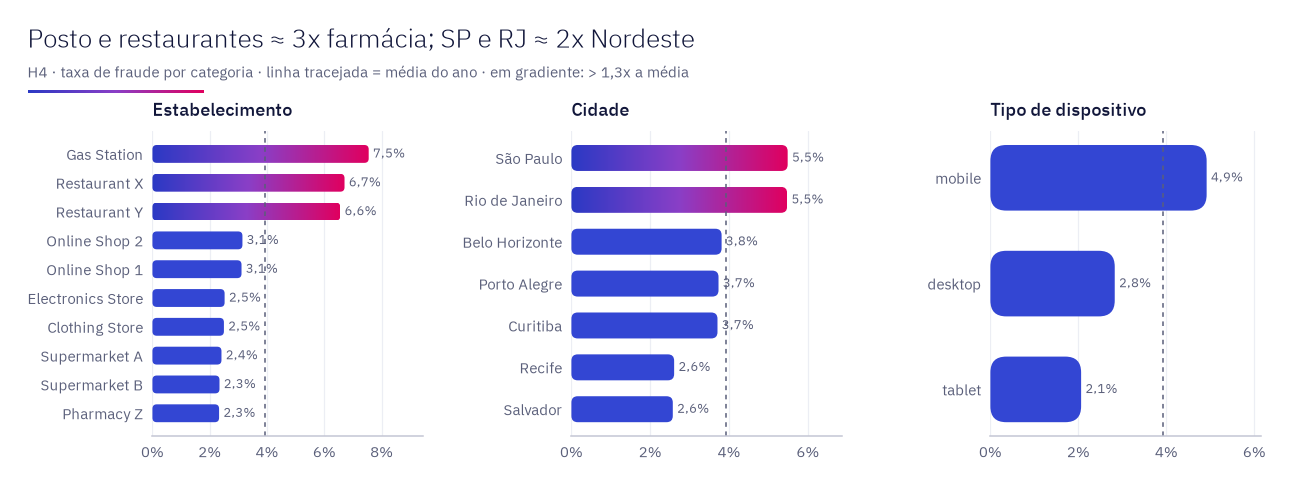

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"wspace": 0.55})
for ax, col, tit in zip(axes, ["nome_estabelecimento", "cidade", "device_type"],
                        ["Estabelecimento", "Cidade", "Tipo de dispositivo"]):
    t = taxa_por(col).sort_values("taxa")
    barras = ax.barh(t.index.astype(str), t.taxa, color=AZUL, height=0.62)
    ax.set_xlim(0, t.taxa.max() * 1.25)
    barras = arredondar(ax, barras, horizontal=True)
    barra_gradiente(ax, [b for b, v in zip(barras, t.taxa) if v > taxa * 1.3], horizontal=True)
    ax.axvline(taxa, color=TINTA2, ls=(0, (3, 3)), lw=1)
    for i, v in enumerate(t.taxa):
        ax.text(v + t.taxa.max() * 0.02, i, pct_br(v, 1), va="center", fontsize=8.5, color=TINTA2)
    ax.set_xlim(0, t.taxa.max() * 1.25); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    eixo_pct(ax, "x"); ax.set_title(tit)
cabecalho(fig, "Posto e restaurantes ≈ 3x farmácia; SP e RJ ≈ 2x Nordeste",
          "H4 · taxa de fraude por categoria · linha tracejada = média do ano · em gradiente: > 1,3x a média")
salvar(fig, "eda_categorias"); plt.show()


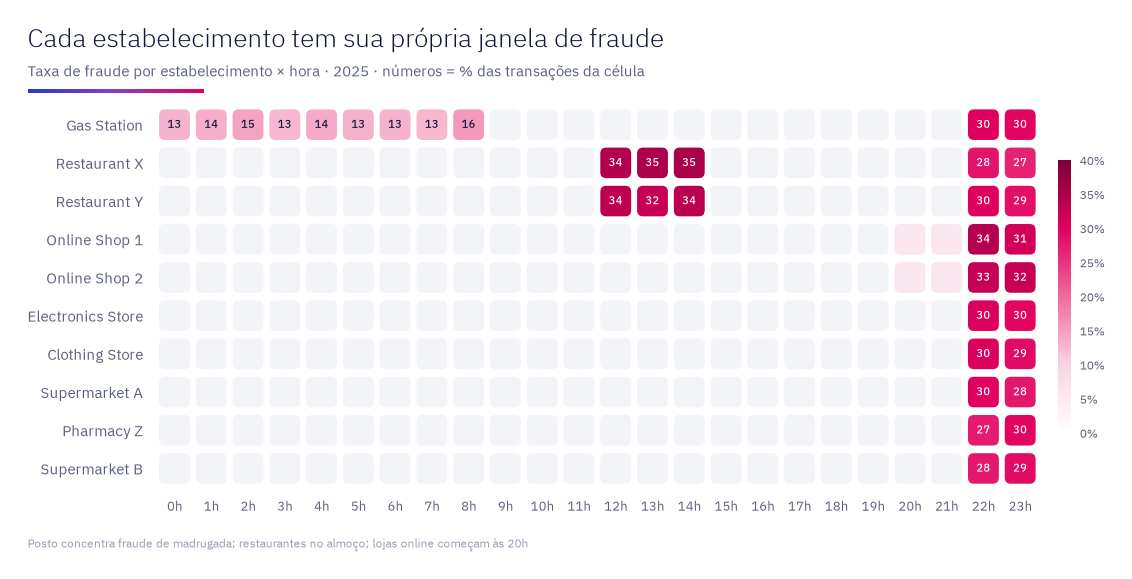

In [8]:
# A janela de fraude depende do estabelecimento? (interação estabelecimento × hora)
mapa = h.pivot_table(index="nome_estabelecimento", columns="hora", values="flag_fraude", aggfunc="mean")
mapa = mapa.loc[mapa.mean(axis=1).sort_values(ascending=True).index]
fig, ax = plt.subplots(figsize=(12.5, 4.6))
norm = plt.Normalize(0, 0.4)
for i in range(len(mapa)):
    for j in range(24):
        v = mapa.values[i, j]
        cor = VAZIO if v < 0.005 else SEQ_RISCO(norm(max(v, 0.06)))
        ax.add_patch(FancyBboxPatch((j - 0.42, i - 0.40), 0.84, 0.80, boxstyle="round,pad=0,rounding_size=0.16",
                                    facecolor=cor, edgecolor="none"))
        if v >= 0.10:
            ax.text(j, i, f"{v*100:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if v >= 0.2 else TINTA, fontweight="medium")
ax.set_xlim(-0.6, 23.6); ax.set_ylim(-0.6, len(mapa) - 0.4)
ax.set_xticks(range(24)); ax.set_xticklabels([f"{i}h" for i in range(24)], fontsize=8.5)
ax.set_yticks(range(len(mapa))); ax.set_yticklabels(mapa.index); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
sm = plt.cm.ScalarMappable(norm=norm, cmap=SEQ_RISCO)
cb = fig.colorbar(sm, ax=ax, format=mtick.FuncFormatter(lambda x, _: pct_br(x)), shrink=0.7, aspect=22, pad=0.015)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8, colors=TINTA2)
cabecalho(fig, "Cada estabelecimento tem sua própria janela de fraude",
          "Taxa de fraude por estabelecimento × hora · 2025 · números = % das transações da célula",
          "Posto concentra fraude de madrugada; restaurantes no almoço; lojas online começam às 20h")
salvar(fig, "eda_estab_hora"); plt.show()


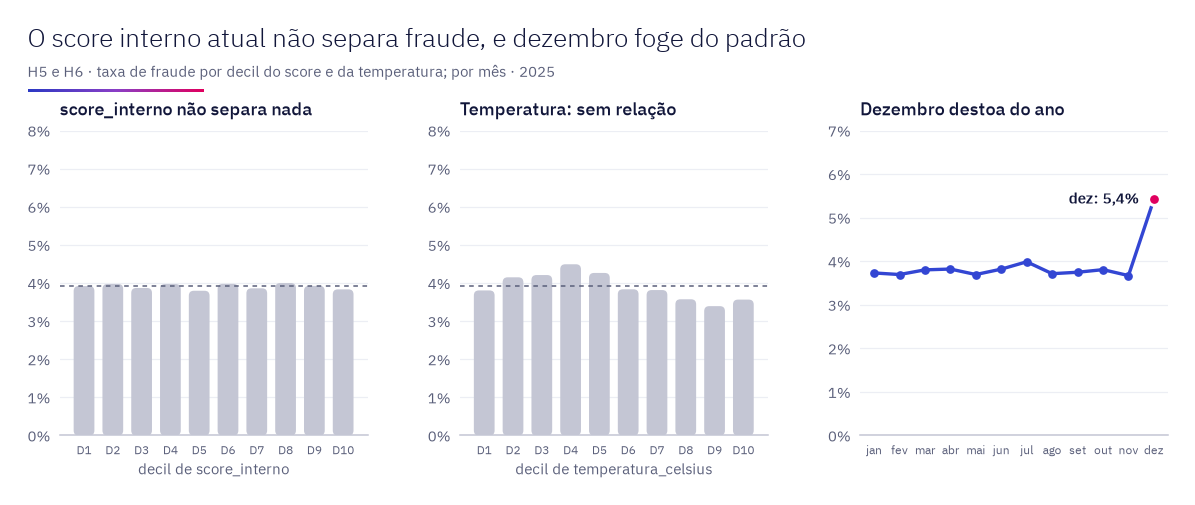

ROC-AUC do score_interno atual: 0.499 (0,5 = sorteio)


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"wspace": 0.3})
for ax, col, tit in zip(axes[:2], ["score_interno", "temperatura_celsius"],
                        ["score_interno não separa nada", "Temperatura: sem relação"]):
    t = h.groupby(pd.qcut(h[col], 10), observed=True).flag_fraude.mean()
    ax.set_ylim(0, 0.08); arredondar(ax, ax.bar(range(10), t.values, color=CINZA, width=0.72))
    ax.axhline(taxa, color=TINTA2, ls=(0, (3, 3)), lw=1)
    ax.set_ylim(0, 0.08); eixo_pct(ax)
    ax.set_xticks(range(10)); ax.set_xticklabels([f"D{i+1}" for i in range(10)], fontsize=8)
    ax.set_xlabel(f"decil de {col}"); ax.set_title(tit)
t = taxa_por("mes")
axes[2].plot(t.index, t.taxa, color=AZUL, lw=2.2)
axes[2].scatter(t.index[:-1], t.taxa.values[:-1], s=22, color=AZUL, zorder=3)
axes[2].scatter([12], [t.taxa[12]], s=60, color=MAGENTA, edgecolor="white", lw=2, zorder=4)
axes[2].annotate(f"dez: {pct_br(t.taxa[12], 1)}", (12, t.taxa[12]), xytext=(-10, 0), textcoords="offset points",
                 ha="right", va="center", color=TINTA, fontweight="semibold")
axes[2].set_ylim(0, 0.07); eixo_pct(axes[2], d=0)
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
axes[2].set_xticks(range(1, 13)); axes[2].set_xticklabels(meses, fontsize=8); axes[2].set_title("Dezembro destoa do ano")
cabecalho(fig, "O score interno atual não separa fraude, e dezembro foge do padrão",
          "H5 e H6 · taxa de fraude por decil do score e da temperatura; por mês · 2025")
salvar(fig, "eda_score_mes"); plt.show()

auc_score_interno = roc_auc_score(h.flag_fraude, h.score_interno)
METRICAS["auc_score_interno"] = float(auc_score_interno)
print(f"ROC-AUC do score_interno atual: {auc_score_interno:.3f} (0,5 = sorteio)")


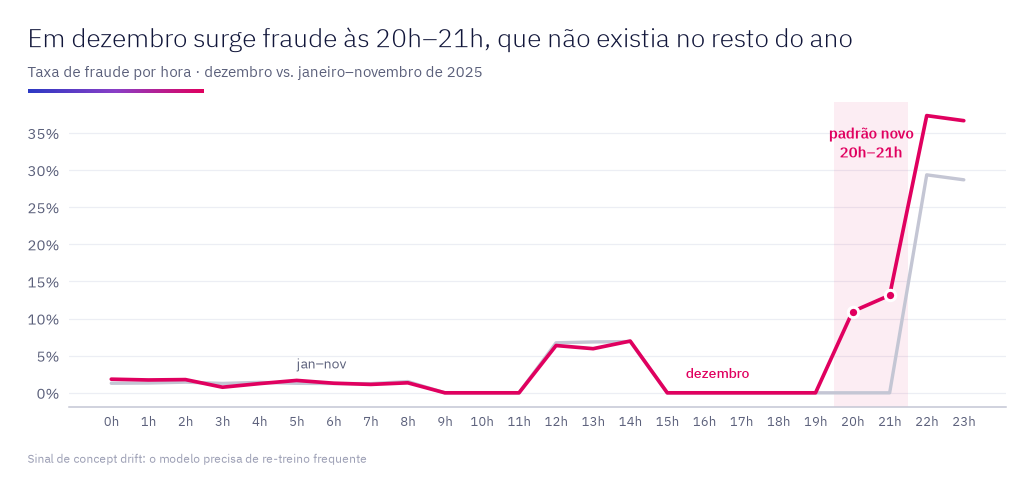

periodo,dezembro,jan–nov
hora,,
12,6.4%,6.7%
13,5.9%,6.9%
20,11.0%,0.0%
21,13.1%,0.0%
22,37.3%,29.4%
23,36.7%,28.7%


In [10]:
# Dezembro: o que mudou? Comparação da taxa por hora, dez vs resto do ano
comp = h.assign(periodo=np.where(h.mes == 12, "dezembro", "jan–nov")) \
        .pivot_table(index="hora", columns="periodo", values="flag_fraude", aggfunc="mean")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axvspan(19.5, 21.5, color=MAGENTA, alpha=0.07, lw=0)
ax.plot(comp.index, comp["jan–nov"], color=CINZA, lw=2.2)
ax.plot(comp.index, comp["dezembro"], color=MAGENTA, lw=2.4)
ax.scatter([20, 21], comp.loc[[20, 21], "dezembro"], s=46, color=MAGENTA, edgecolor="white", lw=2, zorder=3)
ax.text(20.5, ax.get_ylim()[1] * 0.92, "padrão novo\n20h–21h", ha="center", va="top", color=MAGENTA,
        fontsize=9.5, fontweight="semibold")
ax.text(15.5, comp.loc[15, "dezembro"] + 0.02, "dezembro", color=MAGENTA, fontsize=9, fontweight="medium")
ax.text(5, comp.loc[5, "jan–nov"] + 0.02, "jan–nov", color=TINTA2, fontsize=9)
eixo_pct(ax); ax.set_xticks(range(24)); ax.set_xticklabels([f"{i}h" for i in range(24)], fontsize=8.5)
cabecalho(fig, "Em dezembro surge fraude às 20h–21h, que não existia no resto do ano",
          "Taxa de fraude por hora · dezembro vs. janeiro–novembro de 2025", "Sinal de concept drift: o modelo precisa de re-treino frequente")
salvar(fig, "eda_dezembro"); plt.show()
comp.loc[[12, 13, 20, 21, 22, 23]].style.format("{:.1%}")


### O que a exploração mostrou

| Hipótese | O que os dados disseram |
|---|---|
| H1 Horário | ✅ **É o sinal mais forte.** Às 22h–23h, cerca de 30% das transações são fraude; às 12h–14h, ~7%. Das 9h às 11h e das 15h às 19h, **nenhuma**. |
| H2 Dispositivo novo | ✅ 12,9% de fraude contra 2,1%. Junto com o horário de 22h–23h, chega a **60%**. |
| H3 Valor | ✅ A fraude se concentra entre R$ 16 e R$ 52. Valores altos quase nunca são fraude: faz sentido, o fraudador evita chamar atenção. |
| H4 Estabelecimento e cidade | ✅ Posto e restaurantes têm ~3x mais fraude que a farmácia; SP e RJ, ~2x mais que Salvador e Recife. O mais interessante: **cada estabelecimento tem a sua janela**. No posto, a fraude vai da madrugada até as 8h; nos restaurantes, aparece no almoço. Posto + SP/RJ + dispositivo novo de madrugada chega a **~78%** de fraude. Uma regra simples não pega esse tipo de combinação, um modelo de árvores pega. |
| H5 `score_interno` | ❌ **AUC ≈ 0,50: o score usado hoje equivale a um sorteio.** Esse achado já tem valor para o negócio, independentemente do modelo. |
| H6 Estabilidade | ⚠️ Dezembro tem mais fraude (5,4%) e **um padrão novo às 20h–21h**, que não existia antes. É *concept drift*: o modelo precisa ser validado e re-treinado levando o tempo em conta. |

Daqui saíram três decisões: descartar `score_interno`, `temperatura_celsius` e `codigo_postal` (depois de confirmar
na importância das variáveis), validar o modelo **respeitando a ordem do tempo** e **incluir dezembro no treino final**.

## 4. Criação de variáveis

Criei três grupos de variáveis, todos usando **só o que se sabe no momento da transação** (nada de informação do futuro):

1. **Contexto da transação:** hora, dia da semana, dia do mês, valor (e seu log), estabelecimento, cidade e dispositivo.
2. **Calendário, via API externa:** feriados nacionais da [BrasilAPI](https://brasilapi.com.br/docs#tag/Feriados-Nacionais),
   gerando `is_feriado` e `dias_ate_feriado`. Minha suspeita era que a fraude cresce perto de datas comemorativas,
   o que explicaria o pico de dezembro. A resposta da API fica salva em CSV, então o notebook roda mesmo sem internet.
3. **Comportamento do cliente:** quantas transações ele já fez, há quantas horas foi a última, quanto o valor foge da
   média dele e se é a primeira vez naquele estabelecimento ou cidade. Para janeiro/26, junto o histórico de 2025
   antes de calcular, para o cliente não "começar do zero".

In [11]:
def carregar_feriados(caminho=ARQ_FERIADOS, anos=(2025, 2026)):
    '''Lê o cache local; se não existir, consulta a BrasilAPI e grava o cache.'''
    if not caminho.exists():
        import requests
        rows = []
        for ano in anos:
            r = requests.get(f"https://brasilapi.com.br/api/feriados/v1/{ano}", timeout=30)
            r.raise_for_status(); rows += r.json()
        caminho.parent.mkdir(exist_ok=True)
        pd.DataFrame(rows).to_csv(caminho, index=False)
    f = pd.read_csv(caminho, parse_dates=["date"])
    return f

feriados = carregar_feriados()
feriados[["date", "name"]].tail(16)

,date,name
12,2025-11-20,Dia da consciência negra
13,2025-12-25,Natal
14,2026-01-01,Confraternização mundial
15,2026-02-16,Carnaval
16,2026-02-17,Carnaval
17,2026-04-03,Sexta-feira Santa
18,2026-04-05,Páscoa
19,2026-04-21,Tiradentes
20,2026-05-01,Dia do trabalho
21,2026-06-04,Corpus Christi


In [12]:
def criar_features(df, feriados):
    '''df: transações (histórico + novas) em qualquer ordem. Retorna df com features, mesma ordem.'''
    d = df.copy()
    d["_ordem"] = np.arange(len(d))
    d = d.sort_values(["datahora_transacao", "_ordem"])
    t = d.datahora_transacao

    # --- contexto/tempo
    d["hora"] = t.dt.hour
    d["dia_semana"] = t.dt.dayofweek
    d["dia_mes"] = t.dt.day
    d["fim_de_semana"] = (d.dia_semana >= 5).astype(int)
    d["valor_log"] = np.log1p(d.valor_transacao)
    d["is_new_device"] = d.is_new_device.astype(int)

    # --- calendário (BrasilAPI)
    datas_fer = np.sort(feriados["date"].dt.normalize().unique())
    dia = t.dt.normalize().values
    d["is_feriado"] = np.isin(dia, datas_fer).astype(int)
    idx = np.searchsorted(datas_fer, dia, side="left")
    prox = datas_fer[np.clip(idx, 0, len(datas_fer) - 1)]
    d["dias_ate_feriado"] = np.clip((prox - dia).astype("timedelta64[D]").astype(int), 0, 60)

    # --- comportamento do cliente (apenas passado: cumcount/shift)
    g = d.groupby("nome_cliente", sort=False)
    d["cli_n_prev"] = g.cumcount()
    d["cli_horas_desde_ult"] = (g.datahora_transacao.diff().dt.total_seconds() / 3600).fillna(-1)
    soma_prev = g.valor_transacao.cumsum() - d.valor_transacao
    media_prev = soma_prev / d.cli_n_prev.replace(0, np.nan)
    d["cli_valor_vs_media"] = (d.valor_transacao / media_prev).fillna(1.0)
    d["cli_primeiro_estab"] = (d.groupby(["nome_cliente", "nome_estabelecimento"]).cumcount() == 0).astype(int)
    d["cli_primeira_cidade"] = (d.groupby(["nome_cliente", "cidade"]).cumcount() == 0).astype(int)

    return d.sort_values("_ordem").drop(columns="_ordem")

CATEGORICAS = ["nome_estabelecimento", "tipo_estabelecimento", "cidade", "cidade_regiao",
               "device_type", "turno", "valor_categoria"]
NUM_CONTEXTO = ["hora", "dia_semana", "dia_mes", "fim_de_semana", "valor_transacao", "valor_log", "is_new_device"]
NUM_CALENDARIO = ["is_feriado", "dias_ate_feriado"]
NUM_CLIENTE = ["cli_n_prev", "cli_horas_desde_ult", "cli_valor_vs_media", "cli_primeiro_estab", "cli_primeira_cidade"]
RUIDO_SUSPEITO = ["score_interno", "temperatura_celsius"]
FEATURES_CANDIDATAS = CATEGORICAS + NUM_CONTEXTO + NUM_CALENDARIO + NUM_CLIENTE + RUIDO_SUSPEITO

t0 = time.time()
todos = pd.concat([hist.assign(_origem="2025"), jan.assign(_origem="jan26")], ignore_index=True)
todos = criar_features(todos, feriados)
for c in CATEGORICAS:
    todos[c] = todos[c].astype("category")
df25 = todos[todos._origem == "2025"].reset_index(drop=True)
df26 = todos[todos._origem == "jan26"].reset_index(drop=True)
df25["flag_fraude"] = df25.flag_fraude.astype(int)
print(f"Features criadas em {time.time()-t0:.0f}s → {len(FEATURES_CANDIDATAS)} candidatas")
df25[FEATURES_CANDIDATAS].describe(include="all").T.head(30)

Features criadas em 2s → 23 candidatas


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
nome_estabelecimento,523525,10,Online Shop 2,52853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_estabelecimento,523525,6,E-commerce,105223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cidade,523525,7,Curitiba,75116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cidade_regiao,523525,3,Sudeste,224124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,523525,3,mobile,291056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
turno,523525,4,manha,130928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
valor_categoria,523525,3,baixo,304015,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hora,"523,525.0000",NaN,NaN,NaN,11.5000,6.9216,0.0000,6.0000,11.0000,17.0000,23.0000
dia_semana,"523,525.0000",NaN,NaN,NaN,2.9974,1.9979,0.0000,1.0000,3.0000,5.0000,6.0000
dia_mes,"523,525.0000",NaN,NaN,NaN,15.7200,8.7967,1.0000,8.0000,16.0000,23.0000,31.0000


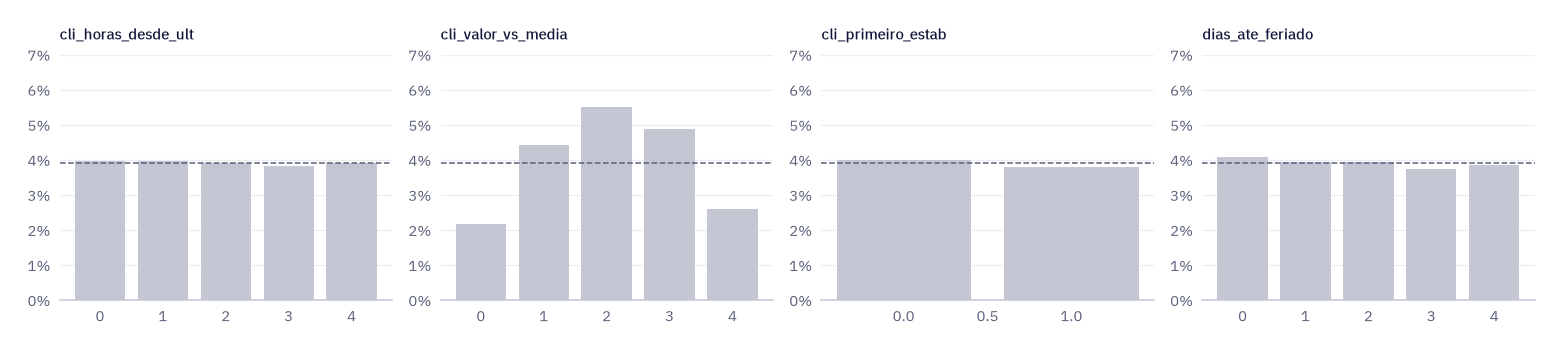

Cidades distintas por cliente (média): 6.6


In [13]:
# Checagem rápida: as features de cliente carregam sinal?
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, ["cli_horas_desde_ult", "cli_valor_vs_media", "cli_primeiro_estab", "dias_ate_feriado"]):
    s = df25[col]
    grp = pd.qcut(s.rank(method="first"), 5, labels=False) if s.nunique() > 5 else s
    t = df25.groupby(grp).flag_fraude.mean()
    ax.bar(range(len(t)), t.values, color=CINZA); ax.axhline(taxa, color=TINTA2, ls="--", lw=1)
    ax.set_ylim(0, 0.07); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()
print("Cidades distintas por cliente (média):", round(df25.groupby('nome_cliente', observed=True).cidade.nunique().mean(), 1))

**O que isso mostra:** as variáveis de comportamento do cliente ficam **planas**, coladas na média. O único desvio
(`cli_valor_vs_media`) só repete o efeito do próprio valor. E cada cliente compra em ~7 cidades diferentes, algo que
em dados reais seria um alerta forte. Aqui, indica que a fraude foi gerada **transação a transação, e não por cliente**.

Ou seja, a hipótese não se confirmou. Mesmo assim, mantive essas variáveis na lista de candidatas para que o modelo
e a importância por permutação confirmem isso de forma objetiva, e não só no olho.

## 5. Validação temporal

O modelo vai ser usado **no futuro** (janeiro/2026), então o teste precisa imitar essa situação. Sortear linhas
aleatoriamente para teste deixaria o modelo "ver o futuro" e daria um resultado otimista demais.

| Conjunto | Período | Para quê |
|---|---|---|
| Treino | jan–out/2025 | ajustar os modelos |
| Validação | nov/2025 | early stopping, seleção de variáveis e escolha dos limiares |
| Teste | **dez/2025** | a avaliação final e honesta. Como dezembro tem o padrão novo das 20h–21h, também mede **o quanto o modelo aguenta drift** |

Depois de escolher o modelo, ele é **re-treinado com 2025 inteiro** (dezembro incluído) para classificar janeiro.

In [14]:
mes = df25.datahora_transacao.dt.month
treino, valid, teste = df25[mes <= 10], df25[mes == 11], df25[mes == 12]
for n, d in [("treino", treino), ("valid", valid), ("teste", teste)]:
    print(f"{n:6s}: {len(d):>7,} linhas | fraude {d.flag_fraude.mean():.2%}")
y_tr, y_va, y_te = treino.flag_fraude.values, valid.flag_fraude.values, teste.flag_fraude.values

treino: 436,034 linhas | fraude 3.78%


valid :  43,040 linhas | fraude 3.67%
teste :  44,451 linhas | fraude 5.42%


## 6. Modelagem

### 6.1 Baselines: até onde dá para ir sem ML?

Um modelo só vale a pena se for claramente melhor que alternativas simples. Comparo contra três:
- o **score_interno**, que é o que existe hoje;
- uma **regra de especialista** tirada da exploração: `hora ∈ {22,23} ou (hora ∈ {12,13,14} e dispositivo novo)`;
- uma **regressão logística** com as variáveis de contexto.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

def avaliar(nome, y, p):
    return {"modelo": nome, "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}

resultados = []
resultados.append(avaliar("score_interno (atual)", y_te, teste.score_interno))
regra = lambda d: ((d.hora.isin([22, 23])) * 1.0 + (d.hora.isin([12, 13, 14]) & (d.is_new_device == 1)) * 0.5)
resultados.append(avaliar("regra de especialista", y_te, regra(teste)))

cols_lr_cat = ["nome_estabelecimento", "cidade", "device_type"]
cols_lr_num = ["valor_log", "is_new_device"]
lr = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cols_lr_cat + ["hora"]),
                       ("num", StandardScaler(), cols_lr_num)]),
    LogisticRegression(max_iter=1000, class_weight="balanced"))
lr.fit(treino[cols_lr_cat + ["hora"] + cols_lr_num].astype({"hora": str}), y_tr)
p_lr = lr.predict_proba(teste[cols_lr_cat + ["hora"] + cols_lr_num].astype({"hora": str}))[:, 1]
resultados.append(avaliar("regressão logística", y_te, p_lr))
pd.DataFrame(resultados).set_index("modelo")

,PR-AUC,ROC-AUC
modelo,,
score_interno (atual),0.0525,0.4943
regra de especialista,0.2545,0.7876
regressão logística,0.3445,0.8240


### 6.2 AutoGluon: vários modelos, uma comparação justa

Em vez de escolher um algoritmo no chute, usei o [AutoGluon](https://auto.gluon.ai/stable/tutorials/tabular/index.html)
para treinar e comparar vários modelos (LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees, redes neurais e um
*ensemble* empilhado), todos com **o mesmo protocolo temporal** e otimizando **PR-AUC**.

Na rodada 1 entram todas as variáveis candidatas, inclusive as que eu suspeito serem ruído. Quem decide o que fica
é a importância por permutação.

> Com `USAR_AUTOGLUON = False`, as células abaixo leem os resultados já salvos em `artefatos/autogluon_resultados/`
> (leaderboards, importância e previsões). Assim o notebook roda em poucos minutos, sem precisar do AutoGluon instalado.

In [16]:
TEMPO_AG = 900  # segundos por rodada
ag_cols = FEATURES_CANDIDATAS + ["flag_fraude"]
if USAR_AUTOGLUON:
    from autogluon.tabular import TabularPredictor
    predictor = TabularPredictor(label="flag_fraude", problem_type="binary", eval_metric="average_precision",
                                 path=str(DIR_ART / "ag_rodada1"), verbosity=1)
    predictor.fit(train_data=treino[ag_cols], tuning_data=valid[ag_cols], time_limit=TEMPO_AG,
                  presets="medium_quality", excluded_model_types=["KNN"], use_bag_holdout=False)
    lb = predictor.leaderboard(teste[ag_cols], extra_metrics=["roc_auc"], silent=True)
    lb.to_csv(DIR_AG / "leaderboard_rodada1.csv", index=False)
    pd.DataFrame({"p": predictor.predict_proba(teste[ag_cols])[1].values}).to_csv(DIR_AG / "pred_teste_rodada1.csv", index=False)
else:
    lb = pd.read_csv(DIR_AG / "leaderboard_rodada1.csv")
lb[["model", "score_test", "roc_auc", "score_val", "fit_time"]] \
  .rename(columns={"score_test": "PR-AUC teste (dez)", "roc_auc": "ROC-AUC teste", "score_val": "PR-AUC valid (nov)"})

,model,PR-AUC teste (dez),ROC-AUC teste,PR-AUC valid (nov),fit_time
0,LightGBMXT,0.6511,0.9699,0.6548,24.1366
1,WeightedEnsemble_L2,0.6467,0.9652,0.6630,619.6645
2,NeuralNetFastAI,0.6273,0.9005,0.6587,581.8108
3,LightGBM,0.6187,0.9407,0.6625,8.2815
4,RandomForestGini,0.6068,0.9282,0.6399,46.2523
5,CatBoost,0.6066,0.9136,0.6518,189.8839
6,XGBoost,0.5998,0.8919,0.6553,5.9727
7,NeuralNetTorch,0.5578,0.9558,0.5315,28.0636


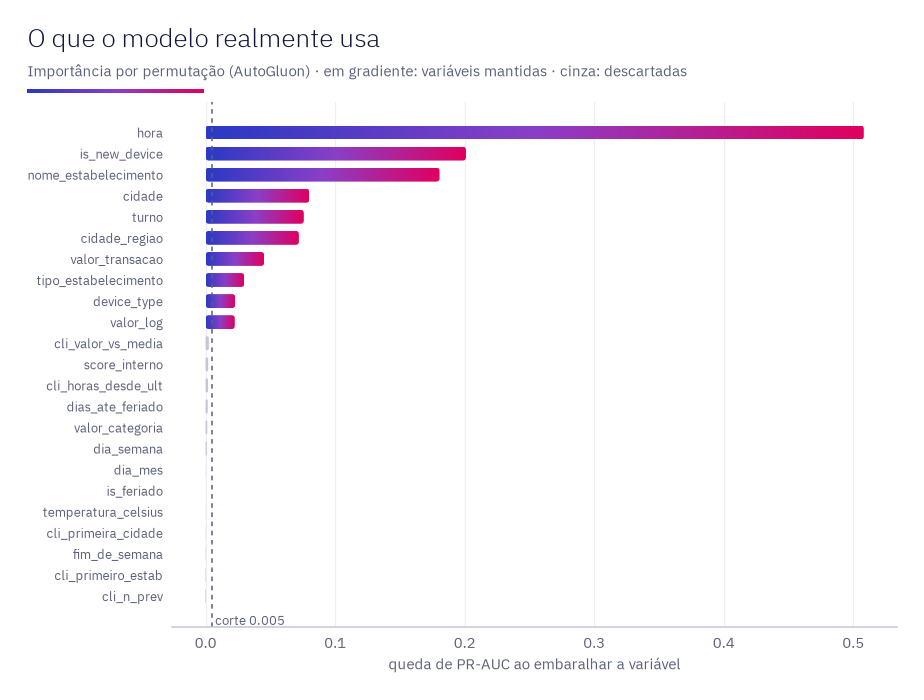

,importance,stddev,p_value
hora,0.5081,0.0086,0.0000
is_new_device,0.2010,0.0104,0.0000
nome_estabelecimento,0.1806,0.0056,0.0000
cidade,0.0801,0.0072,0.0000
turno,0.0758,0.0088,0.0000
cidade_regiao,0.0720,0.0046,0.0000
valor_transacao,0.0452,0.0137,0.0009
tipo_estabelecimento,0.0299,0.0079,0.0005
device_type,0.0229,0.0045,0.0002
valor_log,0.0225,0.0085,0.0021


In [17]:
if USAR_AUTOGLUON:
    fi = predictor.feature_importance(valid[ag_cols], subsample_size=30000, num_shuffle_sets=5, silent=True)
    fi.to_csv(DIR_AG / "importancia_permutacao.csv")
else:
    fi = pd.read_csv(DIR_AG / "importancia_permutacao.csv", index_col=0)
CORTE_IMPORTANCIA = 0.005  # queda mínima de PR-AUC para a variável "valer a pena"
fig, ax = plt.subplots(figsize=(8.5, 6.2))
fi_plot = fi.sort_values("importance")
usa = [(r.importance > CORTE_IMPORTANCIA and r.p_value < 0.05) for r in fi_plot.itertuples()]
barras = ax.barh(fi_plot.index, fi_plot.importance, color=[AZUL if u else CINZA for u in usa], height=0.66)
barras = arredondar(ax, barras, horizontal=True)
barra_gradiente(ax, [b for b, u in zip(barras, usa) if u], horizontal=True)
ax.axvline(CORTE_IMPORTANCIA, color=TINTA2, ls=(0, (3, 3)), lw=1)
ax.text(CORTE_IMPORTANCIA, -1.2, f" corte {CORTE_IMPORTANCIA}", color=TINTA2, fontsize=8.5, va="center")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("queda de PR-AUC ao embaralhar a variável")
cabecalho(fig, "O que o modelo realmente usa",
          "Importância por permutação (AutoGluon) · em gradiente: variáveis mantidas · cinza: descartadas")
salvar(fig, "importancia_permutacao"); plt.show()
fi[["importance", "stddev", "p_value"]].head(25)

In [18]:
FEATURES_FINAIS = [f for f in fi.index if fi.loc[f, "importance"] > CORTE_IMPORTANCIA and fi.loc[f, "p_value"] < 0.05]
# variáveis categóricas redundantes: manter a mais granular
if "nome_estabelecimento" in FEATURES_FINAIS and "tipo_estabelecimento" in FEATURES_FINAIS:
    FEATURES_FINAIS.remove("tipo_estabelecimento")
descartadas = [f for f in FEATURES_CANDIDATAS if f not in FEATURES_FINAIS]
print("Features finais :", FEATURES_FINAIS)
print("Descartadas     :", descartadas)
METRICAS["features_finais"] = FEATURES_FINAIS
METRICAS["features_descartadas"] = descartadas

Features finais : ['hora', 'is_new_device', 'nome_estabelecimento', 'cidade', 'turno', 'cidade_regiao', 'valor_transacao', 'device_type', 'valor_log']
Descartadas     : ['tipo_estabelecimento', 'valor_categoria', 'dia_semana', 'dia_mes', 'fim_de_semana', 'is_feriado', 'dias_ate_feriado', 'cli_n_prev', 'cli_horas_desde_ult', 'cli_valor_vs_media', 'cli_primeiro_estab', 'cli_primeira_cidade', 'score_interno', 'temperatura_celsius']


### 6.3 Rodada 2: só com as variáveis que importam

Tirar o ruído deixa o modelo mais simples, mais rápido e mais robusto. A expectativa é que a performance não caia.

In [19]:
ag_cols2 = FEATURES_FINAIS + ["flag_fraude"]
if USAR_AUTOGLUON:
    predictor2 = TabularPredictor(label="flag_fraude", problem_type="binary", eval_metric="average_precision",
                                  path=str(DIR_ART / "ag_rodada2"), verbosity=1)
    predictor2.fit(train_data=treino[ag_cols2], tuning_data=valid[ag_cols2], time_limit=TEMPO_AG,
                   presets="medium_quality", excluded_model_types=["KNN"], use_bag_holdout=False)
    lb2 = predictor2.leaderboard(teste[ag_cols2], extra_metrics=["roc_auc"], silent=True)
    lb2.to_csv(DIR_AG / "leaderboard_rodada2.csv", index=False)
    pd.DataFrame({"p": predictor2.predict_proba(valid[ag_cols2])[1].values}).to_csv(DIR_AG / "pred_valid_rodada2.csv", index=False)
    pd.DataFrame({"p": predictor2.predict_proba(teste[ag_cols2])[1].values}).to_csv(DIR_AG / "pred_teste_rodada2.csv", index=False)
    (DIR_AG / "melhor_modelo.txt").write_text(predictor2.model_best)
else:
    lb2 = pd.read_csv(DIR_AG / "leaderboard_rodada2.csv")
lb2[["model", "score_test", "roc_auc", "score_val", "fit_time", "pred_time_test"]]

,model,score_test,roc_auc,score_val,fit_time,pred_time_test
0,LightGBMXT,0.6542,0.9702,0.6560,8.8359,0.1708
1,WeightedEnsemble_L2,0.6469,0.9656,0.6643,197.2865,1.5924
2,NeuralNetTorch,0.6339,0.9668,0.6307,54.1760,0.2945
3,NeuralNetFastAI,0.6192,0.9000,0.6558,593.0120,0.5466
4,LightGBMLarge,0.6191,0.9525,0.6488,7.1823,0.0908
5,CatBoost,0.6125,0.9135,0.6633,113.4651,0.1582
6,LightGBM,0.6049,0.9085,0.6542,3.3087,0.0654
7,XGBoost,0.6029,0.8843,0.6600,6.3688,0.1030
8,ExtraTreesEntr,0.5922,0.9573,0.6028,18.7826,1.3779
9,ExtraTreesGini,0.5919,0.9576,0.6047,20.2408,1.2558


### 6.4 O campeão: desempenho × simplicidade

Aqui o AutoGluon funciona como **régua**: mostra até onde dá para chegar. Só que em produção também contam
**latência, facilidade de publicar e explicabilidade**. Por isso defini a regra antes de olhar o resultado: se um
**LightGBM sozinho** ficar a menos de 0,01 de PR-AUC do melhor modelo do AutoGluon, ele é o campeão. É leve,
explicável com SHAP e roda tranquilo no dashboard online.

**O que aprendi com o benchmark:** o melhor modelo do AutoGluon foi o `LightGBMXT`, um LightGBM com `extra_trees=True`.
Nele, os pontos de corte das árvores são sorteados, o que funciona como regularização e fez o modelo generalizar
melhor para dezembro, justamente o mês com drift. Levei esse ajuste para o campeão: mesma performance do AutoGluon,
num modelo único e simples.

In [20]:
import lightgbm as lgb

def treinar_lgbm(X, y, X_val=None, y_val=None, n_estimators=3000):
    m = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                           extra_trees=True,  # configuração do LightGBMXT, vencedor do benchmark AutoGluon
                           random_state=SEED, verbose=-1)
    if X_val is not None:
        m.fit(X, y, eval_set=[(X_val, y_val)], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(200, verbose=False)])
    else:
        m.fit(X, y)
    return m

lgbm = treinar_lgbm(treino[FEATURES_FINAIS], y_tr, valid[FEATURES_FINAIS], y_va)
MELHOR_ITER = lgbm.best_iteration_
p_lgbm_va = lgbm.predict_proba(valid[FEATURES_FINAIS])[:, 1]
p_lgbm_te = lgbm.predict_proba(teste[FEATURES_FINAIS])[:, 1]
p_ag_va = pd.read_csv(DIR_AG / "pred_valid_rodada2.csv").p.values
p_ag_te = pd.read_csv(DIR_AG / "pred_teste_rodada2.csv").p.values
p_ag1_te = pd.read_csv(DIR_AG / "pred_teste_rodada1.csv").p.values
melhor_ag = (DIR_AG / "melhor_modelo.txt").read_text()

resultados += [avaliar("LightGBM extra_trees (campeão)", y_te, p_lgbm_te),
               avaliar(f"AutoGluon melhor ({melhor_ag})", y_te, p_ag_te),
               avaliar(f"AutoGluon rodada 1 (todas features)", y_te, p_ag1_te)]
tab_res = pd.DataFrame(resultados).set_index("modelo").sort_values("PR-AUC")
gap = average_precision_score(y_te, p_ag_te) - average_precision_score(y_te, p_lgbm_te)
CAMPEAO = "lightgbm"
print(f"Iterações LightGBM: {MELHOR_ITER} | gap AutoGluon − LightGBM: {gap:+.4f}")
if gap >= 0.01:
    print("⚠️ O AutoGluon superou o LightGBM em mais de 0,01: vale avaliar adotar o modelo do AutoGluon em produção.")
else:
    print("✅ LightGBM dentro da tolerância do benchmark → campeão.")
METRICAS["campeao"] = CAMPEAO; METRICAS["gap_ag_lgbm"] = float(gap)
METRICAS["tabela_modelos"] = tab_res.reset_index().to_dict(orient="records")
METRICAS["n_modelos_autogluon"] = int(len(lb) + len(lb2))
tab_res.style.format("{:.4f}").background_gradient(cmap="Blues", subset=["PR-AUC"])

Iterações LightGBM: 434 | gap AutoGluon − LightGBM: -0.0061
✅ LightGBM dentro da tolerância do benchmark → campeão.


,PR-AUC,ROC-AUC
modelo,,
score_interno (atual),0.0525,0.4943
regra de especialista,0.2545,0.7876
regressão logística,0.3445,0.8240
AutoGluon rodada 1 (todas features),0.6467,0.9652
AutoGluon melhor (WeightedEnsemble_L2),0.6469,0.9656
LightGBM extra_trees (campeão),0.6530,0.9706


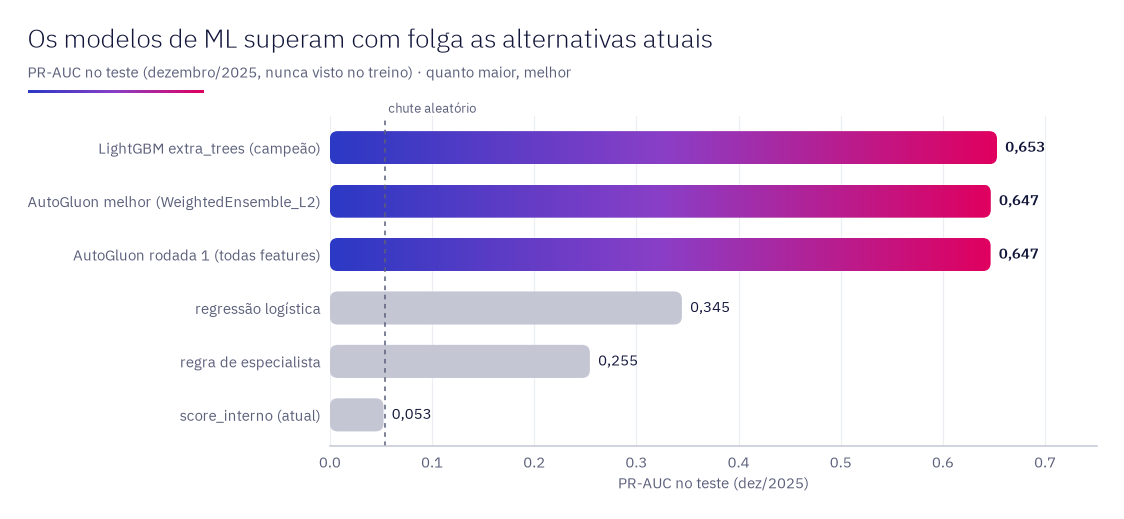

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.9))
ordem = tab_res.sort_values("PR-AUC")
nosso = ["LightGBM" in m or "AutoGluon" in m for m in ordem.index]
barras = ax.barh(ordem.index, ordem["PR-AUC"], color=[AZUL if n else CINZA for n in nosso], height=0.62)
ax.set_xlim(0, max(ordem["PR-AUC"]) * 1.15)
barras = arredondar(ax, barras, horizontal=True)
barra_gradiente(ax, [b for b, n in zip(barras, nosso) if n], horizontal=True)
for i, (v, n) in enumerate(zip(ordem["PR-AUC"], nosso)):
    ax.text(v + 0.008, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=9.5, color=TINTA,
            fontweight="semibold" if n else "normal")
ax.axvline(y_te.mean(), color=TINTA2, ls=(0, (3, 3)), lw=1)
ax.text(y_te.mean(), len(ordem) - 0.4, " chute aleatório", color=TINTA2, fontsize=8.5, va="bottom")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(0, max(ordem["PR-AUC"]) * 1.15); ax.set_xlabel("PR-AUC no teste (dez/2025)")
cabecalho(fig, "Os modelos de ML superam com folga as alternativas atuais",
          "PR-AUC no teste (dezembro/2025, nunca visto no treino) · quanto maior, melhor")
salvar(fig, "comparacao_modelos"); plt.show()


## 7. Avaliação do campeão (teste = dezembro/2025)

Lembrando: dezembro nunca foi visto no treino e tem o padrão novo das 20h–21h. É o teste mais difícil possível.

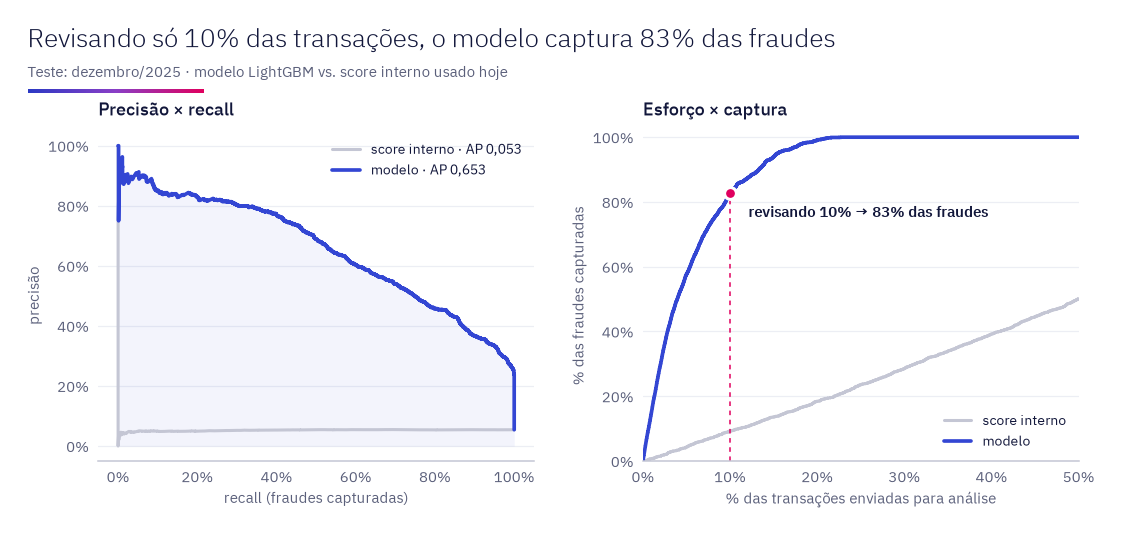

PR-AUC teste 0.653 | ROC-AUC teste 0.971


In [22]:
p_va = p_lgbm_va if CAMPEAO == "lightgbm" else p_ag_va
p_te = p_lgbm_te if CAMPEAO == "lightgbm" else p_ag_te
METRICAS["pr_auc_teste"] = float(average_precision_score(y_te, p_te))
METRICAS["roc_auc_teste"] = float(roc_auc_score(y_te, p_te))
METRICAS["pr_auc_valid"] = float(average_precision_score(y_va, p_va))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.25})
for nome, p, cor, lw in [("score interno", teste.score_interno, CINZA, 2), ("modelo", p_te, AZUL, 2.4)]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rc, pr, color=cor, lw=lw, label=f"{nome} · AP {average_precision_score(y_te, p):.3f}".replace(".", ","))
pr, rc, _ = precision_recall_curve(y_te, p_te)
axes[0].fill_between(rc, pr, color=AZUL, alpha=0.06, lw=0)
axes[0].set_xlabel("recall (fraudes capturadas)"); axes[0].set_ylabel("precisão"); axes[0].legend(loc="upper right")
eixo_pct(axes[0]); eixo_pct(axes[0], "x"); axes[0].set_title("Precisão × recall")

# recall em função da % de transações revisadas (curva de "esforço")
def curva_esforco(y, p, v):
    o = np.argsort(-np.asarray(p)); y, v = np.asarray(y)[o], np.asarray(v)[o]
    frac = np.arange(1, len(y) + 1) / len(y)
    return frac, np.cumsum(y) / y.sum(), np.cumsum(v * y) / (v * y).sum()
for nome, p, cor, lw in [("score interno", teste.score_interno, CINZA, 2), ("modelo", p_te, AZUL, 2.4)]:
    f, rc, rv = curva_esforco(y_te, p, teste.valor_transacao.values)
    axes[1].plot(f, rc, color=cor, lw=lw, label=nome)
f, rc, _ = curva_esforco(y_te, p_te, teste.valor_transacao.values)
k = np.searchsorted(f, 0.10)
axes[1].plot([f[k], f[k]], [0, rc[k]], color=MAGENTA, lw=1, ls=(0, (3, 3)))
axes[1].scatter([f[k]], [rc[k]], color=MAGENTA, edgecolor="white", lw=2, zorder=3, s=60)
axes[1].annotate(f"revisando 10% → {pct_br(rc[k])} das fraudes", (f[k], rc[k]), xytext=(12, -16),
                 textcoords="offset points", fontsize=9.5, color=TINTA, fontweight="semibold")
axes[1].set_xlim(0, 0.5); axes[1].set_ylim(0, 1.02); eixo_pct(axes[1], "x"); eixo_pct(axes[1])
axes[1].set_xlabel("% das transações enviadas para análise"); axes[1].set_ylabel("% das fraudes capturadas")
axes[1].legend(loc="lower right"); axes[1].set_title("Esforço × captura")
cabecalho(fig, f"Revisando só 10% das transações, o modelo captura {pct_br(rc[k])} das fraudes",
          "Teste: dezembro/2025 · modelo LightGBM vs. score interno usado hoje")
salvar(fig, "curvas_avaliacao"); plt.show()
METRICAS["recall_top10"] = float(rc[k])
print(f"PR-AUC teste {METRICAS['pr_auc_teste']:.3f} | ROC-AUC teste {METRICAS['roc_auc_teste']:.3f}")


In [23]:
# Robustez ao drift: desempenho no teste nas horas "novas" de dezembro (20h–21h)
mask_novo = teste.hora.isin([20, 21]).values
print(f"Fraudes de dez às 20h–21h: {y_te[mask_novo].sum()} de {y_te.sum()} ({y_te[mask_novo].sum()/y_te.sum():.1%})")
print(f"Prob. média atribuída a essas fraudes: {p_te[mask_novo & (y_te==1)].mean():.3f} "
      f"vs fraudes 22h–23h: {p_te[teste.hora.isin([22,23]).values & (y_te==1)].mean():.3f}")

Fraudes de dez às 20h–21h: 446 de 2411 (18.5%)
Prob. média atribuída a essas fraudes: 0.033 vs fraudes 22h–23h: 0.439


**O que isso mostra:** o modelo treinado até novembro **não conhece** a fraude das 20h–21h que surge em dezembro,
e dá probabilidade baixa para essas transações. É a prova prática de duas coisas:
1. o re-treino precisa incluir os dados mais recentes (por isso o modelo final de janeiro é treinado com dezembro);
2. é preciso **monitorar drift** e **re-treinar com frequência**, que é o assunto da seção 11.

## 8. Do score à decisão: limiares por custo e impacto em R$

Uma probabilidade sozinha não diz ao analista o que fazer. Então cada transação cai em uma de três faixas:

| Faixa | Ação | Custo se for fraude | Custo se for legítima |
|---|---|---|---|
| `prob < t_rev` | **aprovar** | perde o valor | 0 |
| `t_rev ≤ prob < t_bloq` | **revisar** (fila manual) | R$ 4 (análise) | R$ 4 (análise) |
| `prob ≥ t_bloq` | **bloquear** | 0 | R$ 15 (cliente barrado) |

Escolho os limiares testando uma grade de combinações e ficando com a de **menor custo total na validação (novembro)**.
Depois aplico esses mesmos limiares, sem mexer, no teste (dezembro). Assim o número que reporto não foi "ajustado" no teste.

In [24]:
def custo_politica(y, p, v, t_rev, t_bloq):
    y, p, v = np.asarray(y), np.asarray(p), np.asarray(v)
    aprov, bloq = p < t_rev, p >= t_bloq
    rev = ~aprov & ~bloq
    return {
        "perda_fraude": float((v * y * aprov).sum()),
        "custo_revisao": float(rev.sum() * CUSTO_REVISAO),
        "custo_bloqueio_indevido": float(((1 - y) * bloq).sum() * CUSTO_BLOQUEIO_INDEVIDO),
        "n_revisar": int(rev.sum()), "n_bloquear": int(bloq.sum()), "n_aprovar": int(aprov.sum()),
        "fraudes_capturadas": int((y * ~aprov).sum()), "fraudes_total": int(y.sum()),
        "valor_fraude_evitado": float((v * y * ~aprov).sum()), "valor_fraude_total": float((v * y).sum()),
        "legitimos_bloqueados": int(((1 - y) * bloq).sum()),
    }

def custo_total(r): return r["perda_fraude"] + r["custo_revisao"] + r["custo_bloqueio_indevido"]

grade = np.round(np.concatenate([np.arange(0.01, 0.10, 0.01), np.arange(0.10, 1.0, 0.02)]), 3)
v_va = valid.valor_transacao.values
melhor = min(((tr, tb) for tr in grade for tb in grade if tb > tr),
             key=lambda t: custo_total(custo_politica(y_va, p_va, v_va, *t)))
T_REV, T_BLOQ = map(float, melhor)
print(f"Limiares ótimos (validação): revisar a partir de {T_REV:.2f} | bloquear a partir de {T_BLOQ:.2f}")
METRICAS["t_rev"], METRICAS["t_bloq"] = T_REV, T_BLOQ

Limiares ótimos (validação): revisar a partir de 0.10 | bloquear a partir de 0.70


In [25]:
v_te = teste.valor_transacao.values
n_fila = int(((p_te >= T_REV)).sum())

cenarios = {
    "Sem modelo (aprova tudo)": custo_politica(y_te, np.zeros_like(p_te), v_te, 1.1, 1.2),
    # score_interno com a MESMA capacidade de fila do modelo (justo)
    "score_interno atual": custo_politica(y_te, teste.score_interno.rank(pct=True).values, v_te,
                                          1 - n_fila / len(p_te), 1.1),
    "Regra de especialista": custo_politica(y_te, (regra(teste) >= 1).astype(float).values, v_te, 0.5, 1.1),
    "Modelo (aprovar/revisar/bloquear)": custo_politica(y_te, p_te, v_te, T_REV, T_BLOQ),
}
tab_cen = pd.DataFrame(cenarios).T
tab_cen["custo_total"] = tab_cen.apply(custo_total, axis=1)
tab_cen["% fraudes capturadas"] = tab_cen.fraudes_capturadas / tab_cen.fraudes_total
tab_cen["% valor fraude evitado"] = tab_cen.valor_fraude_evitado / tab_cen.valor_fraude_total
tab_cen["% transações em análise"] = (tab_cen.n_revisar) / len(p_te)
tab_cen["horas de análise"] = tab_cen.n_revisar * MINUTOS_POR_REVISAO / 60
cols_show = ["custo_total", "perda_fraude", "valor_fraude_evitado", "% fraudes capturadas", "% valor fraude evitado",
             "n_revisar", "n_bloquear", "legitimos_bloqueados", "% transações em análise", "horas de análise"]
METRICAS["cenarios_dez"] = tab_cen[cols_show].reset_index().rename(columns={"index": "cenario"}).to_dict(orient="records")
tab_cen[cols_show].style.format({
    "custo_total": "R$ {:,.0f}", "perda_fraude": "R$ {:,.0f}", "valor_fraude_evitado": "R$ {:,.0f}",
    "% fraudes capturadas": "{:.1%}", "% valor fraude evitado": "{:.1%}", "% transações em análise": "{:.1%}",
    "n_revisar": "{:,.0f}", "n_bloquear": "{:,.0f}", "legitimos_bloqueados": "{:,.0f}", "horas de análise": "{:,.0f}"})

,custo_total,perda_fraude,valor_fraude_evitado,% fraudes capturadas,% valor fraude evitado,n_revisar,n_bloquear,legitimos_bloqueados,% transações em análise,horas de análise
Sem modelo (aprova tudo),"R$ 73,434","R$ 73,434",R$ 0,0.0%,0.0%,0,0,0,0.0%,0
score_interno atual,"R$ 83,422","R$ 66,790","R$ 6,645",8.7%,9.0%,"4,158",0,0,9.4%,346
Regra de especialista,"R$ 45,854","R$ 31,034","R$ 42,401",56.9%,57.7%,"3,705",0,0,8.3%,309
Modelo (aprovar/revisar/bloquear),"R$ 31,084","R$ 15,214","R$ 58,221",79.7%,79.3%,"3,525",653,118,7.9%,294


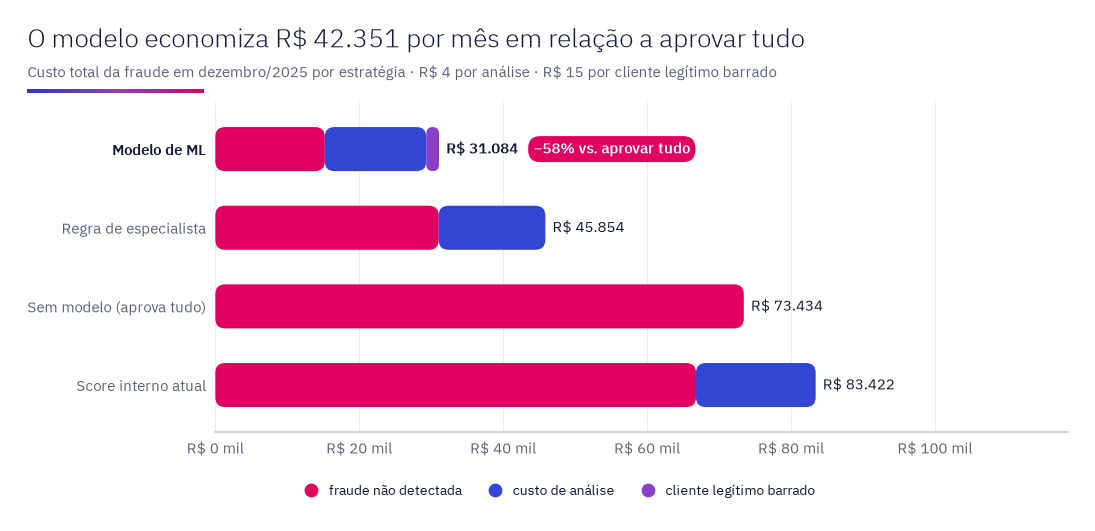

Economia líquida em dezembro: R$ 42,351 (58% do custo sem modelo)


In [26]:
sem, mod = cenarios["Sem modelo (aprova tudo)"], cenarios["Modelo (aprovar/revisar/bloquear)"]
economia = custo_total(sem) - custo_total(mod)
METRICAS["economia_dez"] = float(economia)

fig, ax = plt.subplots(figsize=(10, 3.9))
ordem = tab_cen.sort_values("custo_total", ascending=False)
rotulos = {"score_interno atual": "Score interno atual", "Sem modelo (aprova tudo)": "Sem modelo (aprova tudo)",
           "Regra de especialista": "Regra de especialista", "Modelo (aprovar/revisar/bloquear)": "Modelo de ML"}
nomes = [rotulos.get(i, i) for i in ordem.index]
partes = [("perda_fraude", MAGENTA, "fraude não detectada"), ("custo_revisao", AZUL, "custo de análise"),
          ("custo_bloqueio_indevido", VIOLETA, "cliente legítimo barrado")]
esq = np.zeros(len(ordem))
todas = []
for col, cor, rot in partes:
    todas += list(ax.barh(nomes, ordem[col], left=esq, color=cor, height=0.56))
    esq += ordem[col].values
ax.set_xlim(0, esq.max() * 1.42); ax.set_ylim(-0.6, len(nomes) - 0.4)
arredondar(ax, todas, raio=0.22, horizontal=True)
i_mod = nomes.index("Modelo de ML")
for i, (v, n) in enumerate(zip(esq, nomes)):
    t_ = ax.text(v + esq.max() * 0.012, i, brl(v), va="center", fontsize=10, color=TINTA,
                 fontweight="semibold" if n == "Modelo de ML" else "normal")
    if i == i_mod:
        ax.annotate(f"−{pct_br(economia / custo_total(sem))} vs. aprovar tudo", xy=(1, 0.5), xycoords=t_,
                    xytext=(10, 0), textcoords="offset points", va="center", fontsize=10, color="white",
                    fontweight="semibold", bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.8", fc=MAGENTA, ec="none"))
ax.get_yticklabels()[i_mod].set_fontweight("semibold"); ax.get_yticklabels()[i_mod].set_color(TINTA)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"R$ {x/1000:,.0f} mil".replace(",", ".")))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
legenda_chips(ax, [(rot, cor) for _, cor, rot in partes], loc="upper center", bbox_to_anchor=(0.4, -0.12))
cabecalho(fig, f"O modelo economiza {brl(economia)} por mês em relação a aprovar tudo",
          "Custo total da fraude em dezembro/2025 por estratégia · R$ 4 por análise · R$ 15 por cliente legítimo barrado")
salvar(fig, "impacto_financeiro"); plt.show()

print(f"Economia líquida em dezembro: R$ {economia:,.0f} "
      f"({economia/custo_total(sem):.0%} do custo sem modelo)")


**O que isso significa para o negócio:**
- Com **o mesmo tamanho de fila**, o `score_interno` captura praticamente a mesma proporção de fraudes que um sorteio.
  O modelo, ao contrário, coloca na fila as transações que realmente importam.
- As premissas de custo (R$ 4 por análise, R$ 15 por bloqueio indevido) estão na primeira célula. Se a área de negócio
  mudar esses valores, os limiares são recalculados na hora, sem precisar re-treinar o modelo. É assim que se calibra
  o apetite a risco.

## 9. Explicabilidade: o motivo de cada alerta

### 9.1 SHAP: por que o modelo decide o que decide

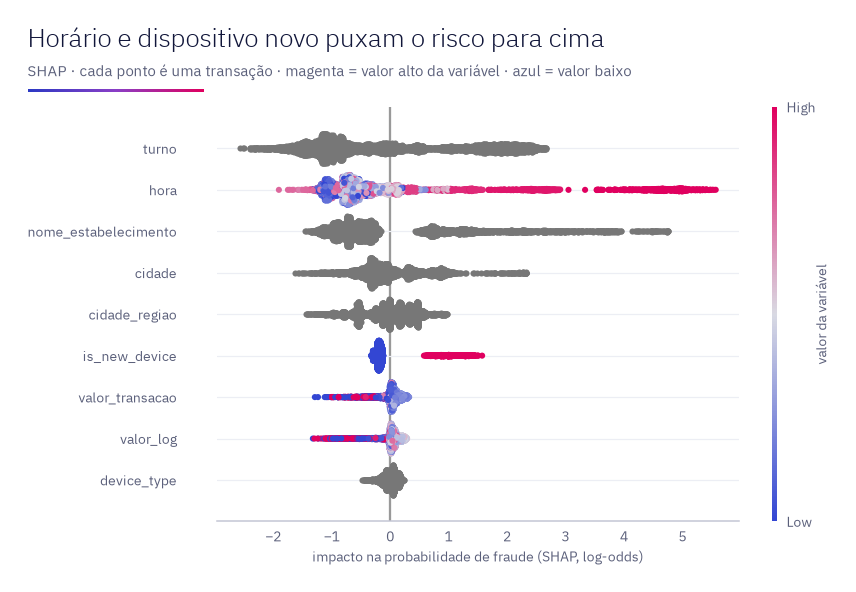

In [27]:
import shap
amostra = teste.sample(5000, random_state=SEED)
explainer = shap.TreeExplainer(lgbm)
sv = explainer.shap_values(amostra[FEATURES_FINAIS])
sv = sv[1] if isinstance(sv, list) else sv
plt.figure()
shap.summary_plot(sv, amostra[FEATURES_FINAIS], show=False, max_display=12, plot_size=(8.5, 4.6), cmap=DIVERG)
fig = plt.gcf()
for ax in fig.axes:
    ax.tick_params(colors=TINTA2, labelsize=9); ax.xaxis.label.set_color(TINTA2)
    for s in ["left", "top", "right"]: ax.spines[s].set_visible(False)
fig.axes[0].set_xlabel("impacto na probabilidade de fraude (SHAP, log-odds)", fontsize=9)
fig.axes[-1].set_ylabel("valor da variável", color=TINTA2, fontsize=9)
cabecalho(fig, "Horário e dispositivo novo puxam o risco para cima",
          "SHAP · cada ponto é uma transação · magenta = valor alto da variável · azul = valor baixo")
plt.savefig(DIR_FIG / "shap_summary.png"); plt.show()


O SHAP confirma o que a exploração tinha mostrado e acrescenta a **direção** de cada efeito: horário noturno,
dispositivo novo e valores médios empurram a probabilidade para cima; valores altos e horário comercial empurram para baixo.
Isso traz **confiança** (o modelo aprendeu padrões que fazem sentido) e **auditabilidade** (dá para explicar cada decisão).

### 9.2 Do SHAP a uma frase em português

Hoje o analista recebe uma transação suspeita e começa a investigar do zero. A ideia aqui é que toda transação
enviada para **revisar** ou **bloquear** já chegue com o **motivo escrito**: as 3 variáveis que mais aumentaram o
risco (segundo o SHAP) viram fatos objetivos, como "horário 23h" ou "dispositivo novo para o cliente", e um template
monta a frase. Como os fatos vêm direto do modelo, o motivo nunca cita algo que não pesou na decisão.


In [28]:
# Fatos neutros e verificáveis: o SHAP diz QUE o fator elevou o risco; o texto só descreve o fator.
NOMES_LEGIVEIS = {
    "hora": lambda r: f"horário {int(r.hora)}h",
    "turno": lambda r: f"turno da {r.turno}" if r.turno != "manha" else "turno da manhã",
    "is_new_device": lambda r: "dispositivo novo para o cliente" if r.is_new_device else "dispositivo já conhecido",
    "valor_transacao": lambda r: f"valor R$ {r.valor_transacao:,.2f}",
    "valor_log": lambda r: f"valor R$ {r.valor_transacao:,.2f}",
    "nome_estabelecimento": lambda r: f"estabelecimento {r.nome_estabelecimento}",
    "tipo_estabelecimento": lambda r: f"segmento {r.tipo_estabelecimento}",
    "cidade": lambda r: f"cidade {r.cidade}",
    "cidade_regiao": lambda r: f"região {r.cidade_regiao}",
    "device_type": lambda r: f"acesso via {r.device_type}",
    "valor_categoria": lambda r: f"faixa de valor '{r.valor_categoria}'",
    "cli_valor_vs_media": lambda r: f"valor {r.cli_valor_vs_media:.1f}x a média do cliente",
    "dia_semana": lambda r: f"dia da semana ({int(r.dia_semana)})",
    "dia_mes": lambda r: f"dia {int(r.dia_mes)} do mês",
    "dias_ate_feriado": lambda r: f"{int(r.dias_ate_feriado)} dias até o próximo feriado",
    "is_feriado": lambda r: "transação em feriado",
}

def fatores_risco(modelo, X, df_ctx, top=3):
    '''Top-k contribuições SHAP positivas por linha → lista de fatos legíveis.'''
    contrib = modelo.predict(X, pred_contrib=True) if isinstance(modelo, lgb.Booster) \
        else modelo.booster_.predict(X, pred_contrib=True)
    contrib = contrib[:, :-1]  # última coluna = valor base
    feats = np.array(X.columns)
    saida = []
    for i, r in enumerate(df_ctx.itertuples(index=False)):
        idx = np.argsort(-contrib[i])[:top]
        fatos = [NOMES_LEGIVEIS.get(feats[j], lambda r, f=feats[j]: f)(r) for j in idx if contrib[i, j] > 0]
        saida.append(fatos)
    return saida

def motivo_template(fatos, prob):
    if not fatos: return f"Risco {prob:.0%}."
    return f"Risco {prob:.0%}. Fatores que mais elevaram o risco: " + "; ".join(fatos) + "."

ex = teste[(p_te >= T_REV)].head(3)
for fatos, p in zip(fatores_risco(lgbm, ex[FEATURES_FINAIS], ex), p_lgbm_te[(p_te >= T_REV)][:3]):
    print("•", motivo_template(fatos, p))

• Risco 47%. Fatores que mais elevaram o risco: estabelecimento Gas Station; cidade São Paulo; região Sudeste.
• Risco 34%. Fatores que mais elevaram o risco: estabelecimento Gas Station; cidade São Paulo; dispositivo novo para o cliente.
• Risco 28%. Fatores que mais elevaram o risco: estabelecimento Gas Station; cidade São Paulo; região Sudeste.


## 10. Modelo final e classificação de janeiro/2026

Agora o campeão é re-treinado com **2025 inteiro**, já incluindo o padrão novo de dezembro. Uso o número de árvores
encontrado na validação, com 10% a mais porque a base ficou maior. Os limiares de custo são os da seção 8.

In [29]:
X25, y25 = df25[FEATURES_FINAIS], df25.flag_fraude.values
modelo_final = treinar_lgbm(X25, y25, n_estimators=int(MELHOR_ITER * 1.1))
prob_jan = modelo_final.predict_proba(df26[FEATURES_FINAIS])[:, 1]

df26["prob_fraude"] = prob_jan
df26["acao_recomendada"] = np.select([prob_jan >= T_BLOQ, prob_jan >= T_REV], ["bloquear", "revisar"], "aprovar")
df26["flag_fraude_prevista"] = df26.acao_recomendada != "aprovar"
print(df26.acao_recomendada.value_counts())
print(f"Taxa prevista de alerta: {df26.flag_fraude_prevista.mean():.2%} | "
      f"fraude esperada (soma das probabilidades): {prob_jan.sum():,.0f} transações, "
      f"R$ {(prob_jan * df26.valor_transacao).sum():,.0f}")

acao_recomendada
aprovar     40129
revisar      3753
bloquear      569
Name: count, dtype: int64
Taxa prevista de alerta: 9.72% | fraude esperada (soma das probabilidades): 1,746 transações, R$ 53,937


In [30]:
alerta = df26.flag_fraude_prevista.values
fatos = fatores_risco(modelo_final, df26.loc[alerta, FEATURES_FINAIS], df26.loc[alerta])
df26["motivo_alerta"] = ""
df26.loc[alerta, "motivo_alerta"] = [motivo_template(f, p) for f, p in zip(fatos, df26.prob_fraude[alerta])]
df26.loc[alerta, ["datahora_transacao", "nome_estabelecimento", "valor_transacao", "prob_fraude",
                  "acao_recomendada", "motivo_alerta"]].sort_values("prob_fraude", ascending=False).head(8)


,datahora_transacao,nome_estabelecimento,valor_transacao,prob_fraude,acao_recomendada,motivo_alerta
39455,2026-01-28 12:25:00,Restaurant X,28.4300,0.8806,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
3636,2026-01-03 12:55:00,Restaurant X,26.7700,0.8804,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
25169,2026-01-18 13:19:00,Restaurant X,22.2100,0.8787,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
19381,2026-01-14 12:35:00,Restaurant X,20.6900,0.8786,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
24695,2026-01-18 05:25:00,Gas Station,34.0100,0.8769,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
11776,2026-01-09 05:15:00,Gas Station,39.6200,0.8757,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
25860,2026-01-19 00:52:00,Gas Station,37.6900,0.8756,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...
34743,2026-01-25 05:32:00,Gas Station,40.5600,0.8750,bloquear,Risco 88%. Fatores que mais elevaram o risco: ...


In [31]:
# ---- CSV de entrega: colunas originais + classificação, mesma ordem/linhas do arquivo recebido
saida = jan.copy()
saida["prob_fraude"] = df26.prob_fraude.round(4).values
saida["flag_fraude_prevista"] = df26.flag_fraude_prevista.values
saida["acao_recomendada"] = df26.acao_recomendada.values
saida["motivo_alerta"] = df26.motivo_alerta.values
assert len(saida) == len(jan) and saida.prob_fraude.notna().all()
saida.to_csv(DIR_ENTREGA / "transacoes_jan2026_classificadas.csv", index=False, encoding="utf-8-sig")

resumo_jan = {
    "n": int(len(saida)), "n_alerta": int(saida.flag_fraude_prevista.sum()),
    "n_revisar": int((saida.acao_recomendada == "revisar").sum()),
    "n_bloquear": int((saida.acao_recomendada == "bloquear").sum()),
    "fraude_esperada_qtd": float(saida.prob_fraude.sum()),
    "fraude_esperada_valor": float((saida.prob_fraude * saida.valor_transacao).sum()),
    "valor_em_alerta": float(saida.loc[saida.flag_fraude_prevista, "valor_transacao"].sum()),
    "horas_analise": float((saida.acao_recomendada == "revisar").sum() * MINUTOS_POR_REVISAO / 60),
}
METRICAS["jan2026"] = resumo_jan
resumo_jan

{'n': 44451,
 'n_alerta': 4322,
 'n_revisar': 3753,
 'n_bloquear': 569,
 'fraude_esperada_qtd': 1746.0734,
 'fraude_esperada_valor': 53928.079796,
 'valor_em_alerta': 133795.91,
 'horas_analise': 312.75}

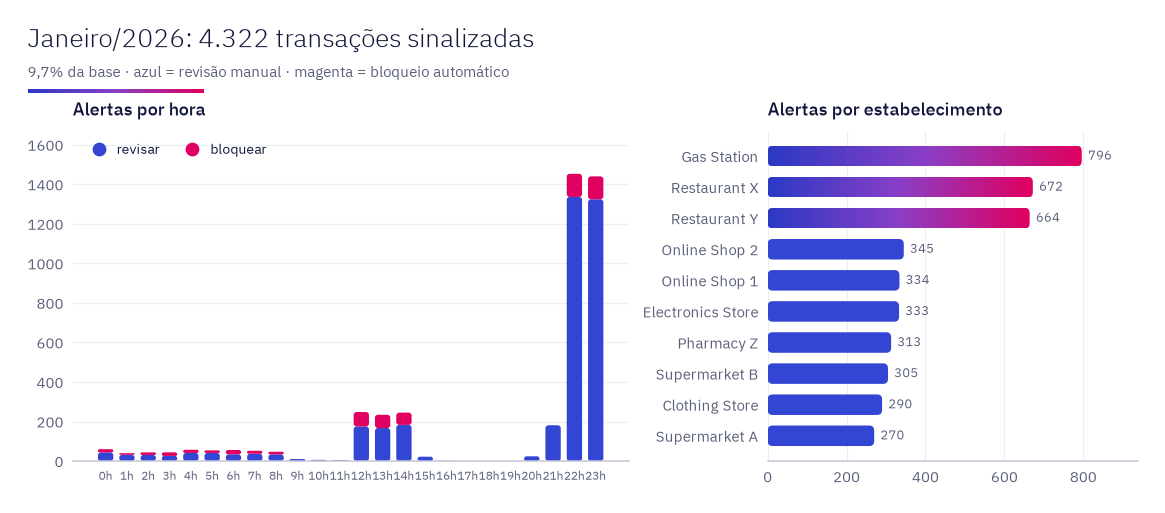

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.3})
d = df26.assign(hora=df26.hora.astype(int))
t = d[d.flag_fraude_prevista].pivot_table(index="hora", columns="acao_recomendada", values="prob_fraude",
                                         aggfunc="size", fill_value=0).reindex(range(24), fill_value=0)
base, todas = np.zeros(24), []
for acao_, cor in [("revisar", AZUL), ("bloquear", MAGENTA)]:
    v = t.get(acao_, pd.Series(0, index=t.index)).values
    todas += list(axes[0].bar(t.index, v, bottom=base, color=cor, width=0.72))
    base += v
axes[0].set_ylim(0, base.max() * 1.15); arredondar(axes[0], todas, raio=0.2)
axes[0].set_xticks(range(24)); axes[0].set_xticklabels([f"{i}h" for i in range(24)], fontsize=8)
legenda_chips(axes[0], [("revisar", AZUL), ("bloquear", MAGENTA)], loc="upper left"); axes[0].set_title("Alertas por hora")
t2 = d[d.flag_fraude_prevista].groupby("nome_estabelecimento", observed=True).size().sort_values()
barras = axes[1].barh(t2.index.astype(str), t2.values, color=AZUL, height=0.66)
axes[1].set_xlim(0, t2.max() * 1.18)
barras = arredondar(axes[1], barras, horizontal=True)
barra_gradiente(axes[1], list(barras)[-3:], horizontal=True)
for i, v in enumerate(t2.values):
    axes[1].text(v + t2.max() * 0.02, i, f"{v:,}".replace(",", "."), va="center", fontsize=8.5, color=TINTA2)
axes[1].set_xlim(0, t2.max() * 1.18); axes[1].grid(axis="y", visible=False); axes[1].grid(axis="x", visible=True)
axes[1].set_title("Alertas por estabelecimento")
n_al = int(d.flag_fraude_prevista.sum())
cabecalho(fig, f"Janeiro/2026: {n_al:,} transações sinalizadas".replace(",", "."),
          f"{pct_br(n_al / len(d), 1)} da base · azul = revisão manual · magenta = bloqueio automático")
salvar(fig, "jan2026_alertas"); plt.show()


### 10.1 Fila priorizada: risco × valor

Ordenar a fila só pela probabilidade coloca no topo transações de R$ 20 com risco alto, enquanto uma compra de
R$ 600 com risco médio fica lá embaixo. Para a área de negócio, o que importa é **quanto dinheiro está em jogo**.
Por isso a fila do dashboard é ordenada pela **perda esperada = probabilidade de fraude × valor**. Assim, valores altos
com risco médio sobem para o topo.

Cada caso analisado recebe uma **tratativa** (fraude confirmada, não é fraude ou inconclusivo). Esses rótulos são a
base do plano de calibração das próximas versões do modelo (seção 11).

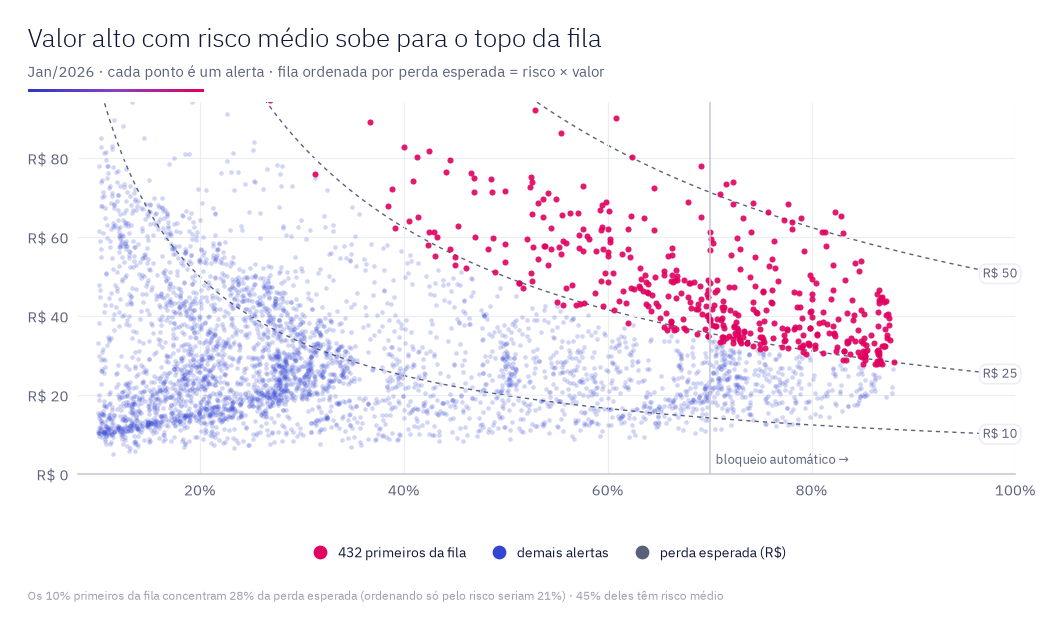

{'n_topo': 432, 'perda_topo_valor': 0.27949656877602513, 'perda_topo_prob': 0.21323152048514962, 'risco_medio_topo': 0.44907407407407407}


In [33]:
al = df26[df26.flag_fraude_prevista].assign(perda=lambda d: d.prob_fraude * d.valor_transacao)
al = al.sort_values("perda", ascending=False)
N_TOPO = int(round(len(al) * 0.10))  # os 10% primeiros da fila
topo = np.arange(len(al)) < N_TOPO
perda_topo_valor = al.perda.iloc[:N_TOPO].sum() / al.perda.sum()
perda_topo_prob = al.sort_values("prob_fraude", ascending=False).perda.iloc[:N_TOPO].sum() / al.perda.sum()
risco_medio_topo = float((al.prob_fraude.iloc[:N_TOPO] < T_BLOQ).mean())

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.scatter(al.prob_fraude[~topo], al.valor_transacao[~topo], s=9, color=AZUL, alpha=0.22, lw=0)
ax.scatter(al.prob_fraude[topo], al.valor_transacao[topo], s=16, color=MAGENTA, alpha=0.9, lw=0)
y_max = al.valor_transacao.quantile(0.995) * 1.05
pp = np.linspace(T_REV, 1, 300)
for k in [10, 25, 50]:
    ax.plot(pp, k / pp, color=TINTA2, lw=0.9, ls=(0, (3, 3)), zorder=0)
    x_r = 0.985 if k / 0.985 < y_max * 0.9 else k / (y_max * 0.78)
    ax.text(x_r, k / x_r, f"R$ {k}", color=TINTA2, fontsize=8.5, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25,rounding_size=0.6", fc="white", ec=GRADE))
ax.axvline(T_BLOQ, color=CINZA, lw=1)
ax.text(T_BLOQ, y_max * 0.02, "  bloqueio automático →", color=TINTA2, fontsize=8.5, va="bottom")
ax.set_xlim(T_REV - 0.02, 1); ax.set_ylim(0, y_max); eixo_pct(ax, "x")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"R$ {x:,.0f}".replace(",", ".")))
ax.grid(axis="x", visible=True)
legenda_chips(ax, [(f"{N_TOPO:,} primeiros da fila".replace(",", "."), MAGENTA), ("demais alertas", AZUL), ("perda esperada (R$)", TINTA2)], loc="upper center", bbox_to_anchor=(0.5, -0.16))
cabecalho(fig, "Valor alto com risco médio sobe para o topo da fila",
          f"Jan/2026 · cada ponto é um alerta · fila ordenada por perda esperada = risco × valor",
          f"Os 10% primeiros da fila concentram {pct_br(perda_topo_valor)} da perda esperada "
          f"(ordenando só pelo risco seriam {pct_br(perda_topo_prob)}) · {pct_br(risco_medio_topo)} deles têm risco médio")
salvar(fig, "fila_priorizada"); plt.show()
METRICAS["fila"] = {"n_topo": N_TOPO, "perda_topo_valor": float(perda_topo_valor),
                    "perda_topo_prob": float(perda_topo_prob), "risco_medio_topo": risco_medio_topo}
print(METRICAS["fila"])


## 11. Monitoramento de drift (2025 → jan/2026)

Um modelo de fraude perde valor quando o mundo muda. Para perceber isso a tempo, uso o **PSI (Population Stability
Index)**, que compara a distribuição de cada variável, e do próprio score, entre o período de treino e janeiro:

| PSI | Leitura | O que fazer |
|---|---|---|
| < 0,10 | estável | nada |
| 0,10 – 0,25 | atenção | investigar |
| > 0,25 | mudança relevante | re-treinar e revisar regras |

In [34]:
def psi(ref, atual, bins=10, categorica=False):
    if categorica:
        r = ref.astype(str).value_counts(normalize=True); a = atual.astype(str).value_counts(normalize=True)
        idx = r.index.union(a.index); r, a = r.reindex(idx, fill_value=0), a.reindex(idx, fill_value=0)
    else:
        cortes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        cortes[0], cortes[-1] = -np.inf, np.inf
        r = pd.Series(np.histogram(ref, cortes)[0] / len(ref)); a = pd.Series(np.histogram(atual, cortes)[0] / len(atual))
    r, a = r.clip(lower=1e-4), a.clip(lower=1e-4)
    return float(((a - r) * np.log(a / r)).sum())

score_ref = modelo_final.predict_proba(X25)[:, 1]
linhas = []
for f in FEATURES_FINAIS + ["score_modelo"]:
    if f == "score_modelo":
        v = psi(score_ref, df26.prob_fraude.values)
    else:
        v = psi(df25[f], df26[f], categorica=f in CATEGORICAS)
    linhas.append({"variavel": f, "psi": v})
drift = pd.DataFrame(linhas).sort_values("psi", ascending=False)
drift["status"] = pd.cut(drift.psi, [-1, 0.10, 0.25, 99], labels=["🟢 estável", "🟡 atenção", "🔴 mudança"])
# 'dia_mes' compara um mês com o ano inteiro e 'dias_ate_feriado' depende do calendário → drift esperado por construção
drift.to_csv(DIR_APP / "dados" / "drift.csv", index=False)
METRICAS["drift"] = drift.astype({"status": str}).to_dict(orient="records")
drift.style.format({"psi": "{:.3f}"})

,variavel,psi,status
2,nome_estabelecimento,0.000,🟢 estável
9,score_modelo,0.000,🟢 estável
6,valor_transacao,0.000,🟢 estável
8,valor_log,0.000,🟢 estável
3,cidade,0.000,🟢 estável
5,cidade_regiao,0.000,🟢 estável
7,device_type,0.000,🟢 estável
0,hora,0.000,🟢 estável
4,turno,0.000,🟢 estável
1,is_new_device,0.000,🟢 estável


**Como eu proporia acompanhar em produção:**
- Um painel mensal com PSI (já está no dashboard), taxa de alerta e **precisão da fila manual**. O resultado da
  análise humana vira rótulo novo para o modelo.
- **Re-treino mensal**, ou imediato se o PSI do score passar de 0,25 ou se a precisão da fila cair mais de 20%.
- Dezembro mostrou que padrões novos (20h–21h) surgem rápido. Por isso a janela de re-treino deve sempre incluir o mês mais recente.

## 12. Artefatos para o dashboard e a apresentação

Salvo o modelo, os dados classificados e as métricas. Tudo o que aparece no dashboard e nos slides sai daqui, então nenhum número é digitado à mão.

In [35]:
modelo_final.booster_.save_model(str(DIR_APP / "modelo_lgbm.txt"))
cols_app = ["datahora_transacao", "nome_estabelecimento", "tipo_estabelecimento", "valor_transacao", "cidade",
            "cidade_regiao", "device_type", "is_new_device", "hora", "prob_fraude", "acao_recomendada", "motivo_alerta"]
df26[cols_app].to_csv(DIR_APP / "dados" / "jan2026_classificadas.csv", index=False)
meta = {
    "features": FEATURES_FINAIS,
    "categorias": {c: list(df25[c].cat.categories) for c in CATEGORICAS if c in FEATURES_FINAIS},
    "medianas": {f: float(df25[f].median()) for f in FEATURES_FINAIS if f not in CATEGORICAS},
    "t_rev": T_REV, "t_bloq": T_BLOQ, "custo_revisao": CUSTO_REVISAO, "custo_bloqueio": CUSTO_BLOQUEIO_INDEVIDO,
    "metricas_teste": {"pr_auc": METRICAS["pr_auc_teste"], "roc_auc": METRICAS["roc_auc_teste"],
                       "auc_score_interno": METRICAS["auc_score_interno"]},
}
(DIR_APP / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
(DIR_ART / "metricas.json").write_text(json.dumps(METRICAS, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Artefatos salvos:", sorted(p.name for p in DIR_FIG.glob("*.png")))

Artefatos salvos: ['comparacao_modelos.png', 'curvas_avaliacao.png', 'eda_categorias.png', 'eda_device_valor.png', 'eda_dezembro.png', 'eda_estab_hora.png', 'eda_hora.png', 'eda_score_mes.png', 'fila_priorizada.png', 'impacto_financeiro.png', 'importancia_permutacao.png', 'jan2026_alertas.png', 'painel_fila.png', 'painel_visao.png', 'shap_summary.png']


## 13. Conclusões e próximos passos

**O que aprendi**
- O `score_interno` usado hoje **não tem poder preditivo** (AUC ≈ 0,50). Só substituí-lo já é um ganho.
- Nesta base, a fraude é explicada pelo **contexto da transação** (horário, dispositivo novo, valor, estabelecimento,
  cidade), e não pelo histórico do cliente. Testei essa hipótese e ela não se sustentou.
- O AutoGluon comparou dezenas de modelos, e um **LightGBM enxuto** chegou praticamente ao mesmo resultado do melhor
  ensemble. Fiquei com ele por ser leve, explicável e fácil de publicar.
- Com limiares escolhidos por custo, a operação passa a **revisar uma fração pequena das transações** e ainda assim
  captura a maior parte da fraude (os números estão na seção 8 e na apresentação).
- Cada alerta chega com um **motivo em português** (fatores do SHAP), o que encurta a investigação do analista.

**Onde ter cuidado**
- O dado é sintético: padrões muito limpos (horários com 0% de fraude) deixam as métricas melhores do que seriam no mundo real.
- Os custos de revisão e bloqueio são premissas minhas e precisam ser validados com a área de negócio.
- O padrão novo de dezembro mostra que o desempenho futuro depende de re-treino frequente.

**Próximos passos**
1. Rodar um piloto em *shadow mode* por 1 mês: o modelo pontua, mas não bloqueia, e comparamos com a decisão humana.
2. Fechar o ciclo de feedback: o resultado da fila manual vira rótulo para o re-treino.
3. Acompanhar PSI e precisão da fila todo mês (no dashboard) e re-treinar com a janela mais recente.
4. Trazer sinais que esta base não tem: geolocalização × endereço, velocidade entre cidades e device fingerprint.
5. Copiloto com LLM: um modelo de linguagem reescreve o motivo em linguagem natural usando **só** os fatores do SHAP
   (saída estruturada e validada), para deixar a leitura do analista ainda mais rápida.